In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

In [35]:
%pip install adjustText

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 12.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [adjustText]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [90]:
df = pd.read_csv("/Users/lisateichmann/Desktop/ONB_gender/LT-301026-onb-request-reconciled.csv")


In [91]:
df["publication_date"] = df["publication_date"].astype("Int64")

In [92]:
display(df.head())
print("Columns:", df.columns.tolist())
print("Number of rows:", len(df))

,File,record_id,author,author_id,Geschlecht,title,publication_date,language,isbns
0,LT_131026_onb_request_after2013_xmlresults.csv,9959032210903338,"Reyer, Sophie","Reyer, Sophie",Weiblich,: izabrane pesme,2022,srp,9788664072113
1,LT_131026_onb_request_after2013_xmlresults.csv,990056743370603338,"Brezina, Thomas","Brezina, Thomas",Männlich,¡Ah del barco fantasma!,2015,spa,9788467582468 | 8467582464
2,LT_131026_onb_request_after2013_xmlresults.csv,990037600490603338,"Nöstlinger, Christine","Nöstlinger, Christine",Weiblich,¡Ojo! ¡Vranek parece totalmente inofensivo!,2010,spa,9788483430873
3,LT_131026_onb_request_after2013_xmlresults.csv,9959219626803338,"Obrecht, Bettina","Obrecht, Bettina",Weiblich,¿Es muy diferente ser viejo?,2024,spa,9788412839524
4,LT_131026_onb_request_after2013_xmlresults.csv,990044392180603338,"Zweig, Stefan","Zweig, Stefan",Männlich,¿Fue él?,2010,spa,9788492649310 | 8492649313


Columns: ['File', 'record_id', 'author', 'author_id', 'Geschlecht', 'title', 'publication_date', 'language', 'isbns']
Number of rows: 32103


In [93]:
column = "Geschlecht"

frequency_table = (
    df[column]
    .value_counts(dropna=False)
    .rename_axis(column)
    .reset_index(name="Count")
)

frequency_table["Percentage"] = (
    frequency_table["Count"]
    / frequency_table["Count"].sum()
    * 100
).round(2)

display(frequency_table)

,Geschlecht,Count,Percentage
0,Männlich,17614,54.87
1,Weiblich,9239,28.78
2,NaN,3038,9.46
3,Unbekannt,2212,6.89


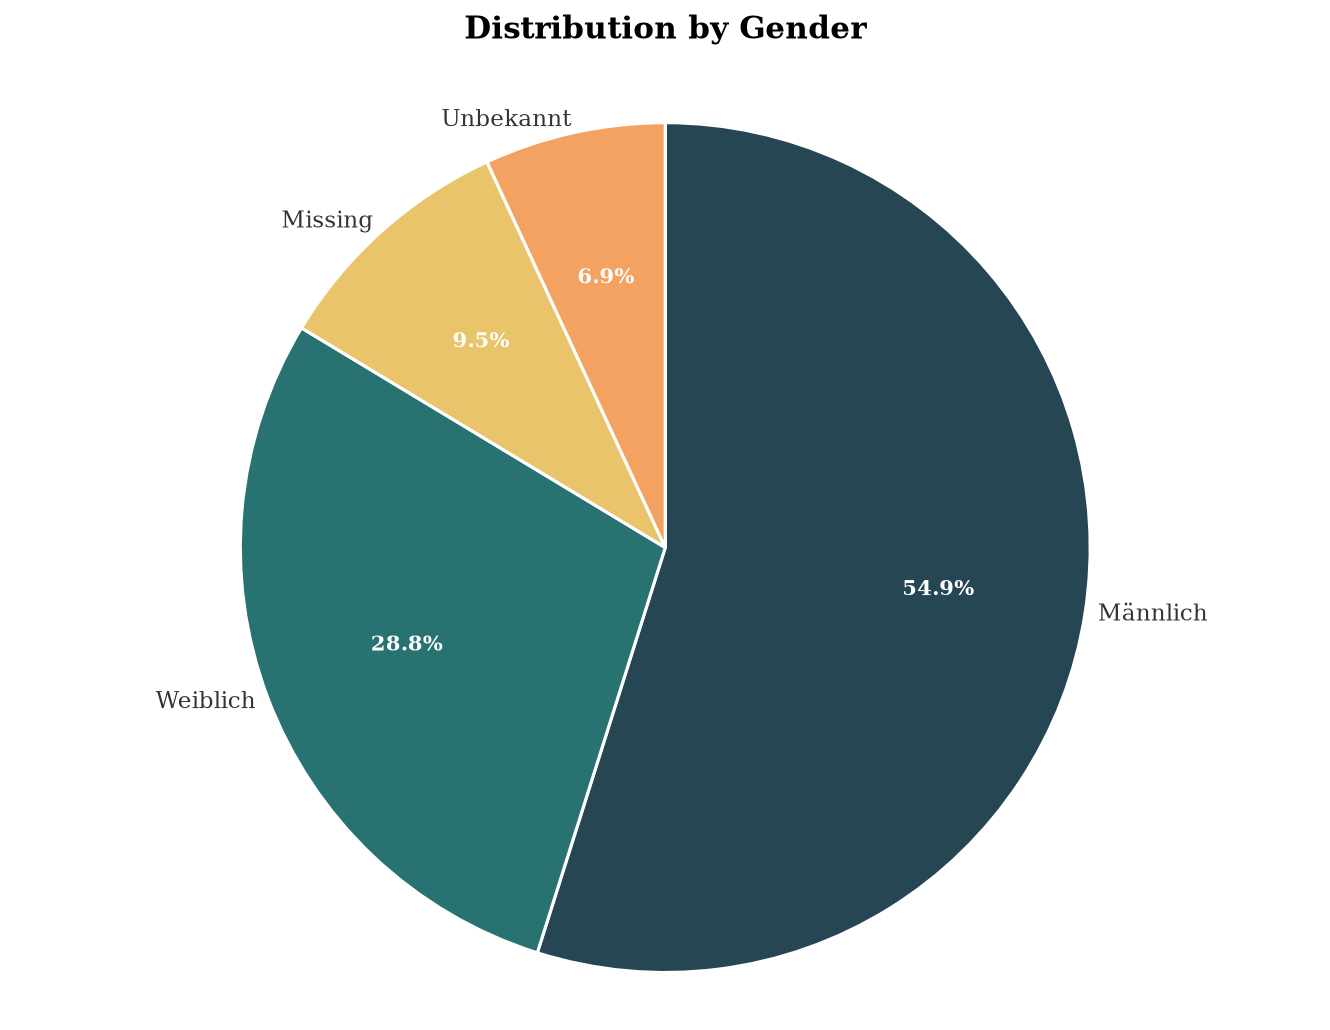

In [ ]:
##Piechart of gender distribution of titles

import matplotlib.pyplot as plt

# Put Männlich first, followed by the other categories
frequency_table = frequency_table.copy()

frequency_table["Geschlecht"] = frequency_table["Geschlecht"].fillna("Missing")

category_order = ["Männlich"] + [
    category
    for category in frequency_table["Geschlecht"].unique()
    if category != "Männlich"
]

frequency_table["Geschlecht"] = pd.Categorical(
    frequency_table["Geschlecht"],
    categories=category_order,
    ordered=True
)

frequency_table = frequency_table.sort_values("Geschlecht")

labels = frequency_table["Geschlecht"].astype(str)
counts = frequency_table["Count"]

# Assign colors consistently to categories
palette = {
    "Männlich": "#264653",
    "Weiblich": "#287271",
    "Divers": "#8AB17D",
    "Missing": "#E9C46A"
}

colors = [
    palette.get(label, "#F4A261")
    for label in labels
]

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

fig, ax = plt.subplots(figsize=(9, 7), facecolor="white")

wedges, texts, autotexts = ax.pie(
    counts,
    labels=labels,
    colors=colors,
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    counterclock=False,
    pctdistance=0.65,
    labeldistance=1.03,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 1.5
    },
    textprops={
        "fontsize": 11,
        "color": "#333333"
    }
)

# Style percentage labels inside wedges
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontweight("bold")
    autotext.set_fontsize(10)

ax.set_title(
    "Distribution by Gender (n=32.103 titles)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.axis("equal")
plt.tight_layout()

# Save high-resolution PNG and vector PDF
plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/LT-131026-onb-gender_piechart.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/LT-131026-onb-gender_piechart.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [95]:
frequency_table.to_csv(
    "/Users/lisateichmann/Desktop/ONB_gender/results/LT-131026-onb-gender-freqs.csv",
    index=False
)

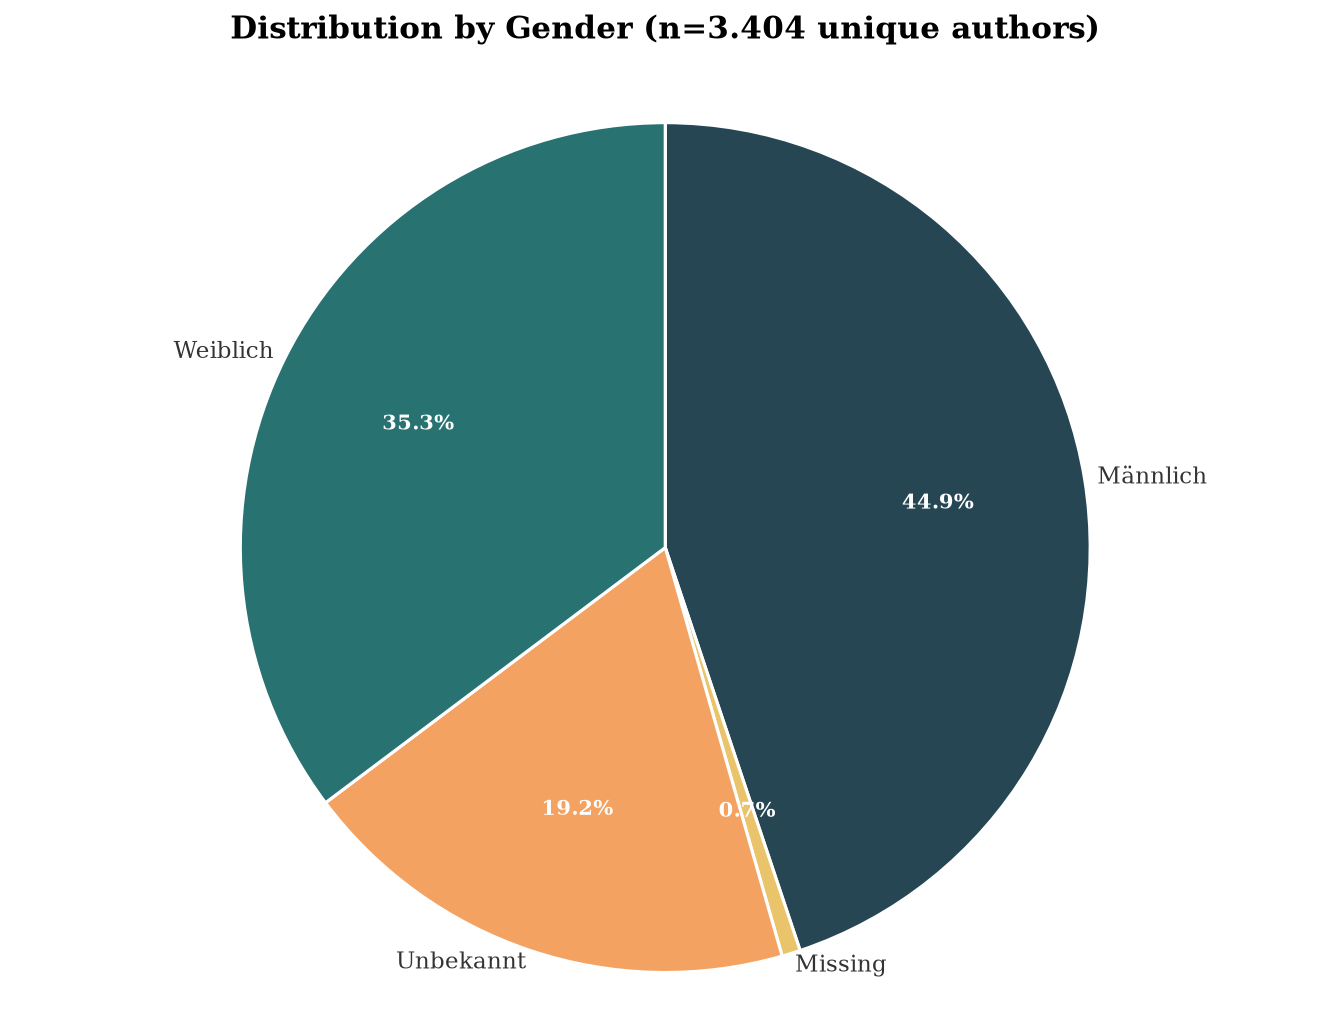

In [118]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Create frequency table based on UNIQUE authors (author_id)
# ---------------------------------------------------------

# Replace `df` with the name of your original dataframe
# This assumes that each author_id has one consistent gender assignment.

author_frequency_table = (
    df[["author_id", "Geschlecht"]]
    .drop_duplicates(subset="author_id")  # keep each author only once
    .copy()
)

# Treat missing gender information as its own category
author_frequency_table["Geschlecht"] = author_frequency_table["Geschlecht"].fillna("Missing")

# Count unique authors per gender category
author_frequency_table = (
    author_frequency_table
    .groupby("Geschlecht", dropna=False)["author_id"]
    .nunique()
    .reset_index(name="Count")
)

# ---------------------------------------------------------
# Order categories
# ---------------------------------------------------------

# Put Männlich first, followed by the other available categories
category_order = ["Männlich"] + [
    category
    for category in author_frequency_table["Geschlecht"].unique()
    if category != "Männlich"
]

author_frequency_table["Geschlecht"] = pd.Categorical(
    author_frequency_table["Geschlecht"],
    categories=category_order,
    ordered=True
)

author_frequency_table = author_frequency_table.sort_values("Geschlecht")

labels = author_frequency_table["Geschlecht"].astype(str)
counts = author_frequency_table["Count"]

# Total number of unique authors, used in the title
n_authors = author_frequency_table["Count"].sum()

# ---------------------------------------------------------
# Colors
# ---------------------------------------------------------

palette = {
    "Männlich": "#264653",
    "Weiblich": "#287271",
    "Divers": "#8AB17D",
    "Missing": "#E9C46A"
}

colors = [
    palette.get(label, "#F4A261")
    for label in labels
]

# ---------------------------------------------------------
# Plot styling
# ---------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

fig, ax = plt.subplots(figsize=(9, 7), facecolor="white")

wedges, texts, autotexts = ax.pie(
    counts,
    labels=labels,
    colors=colors,
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    counterclock=False,
    pctdistance=0.65,
    labeldistance=1.03,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 1.5
    },
    textprops={
        "fontsize": 11,
        "color": "#333333"
    }
)

# Style percentage labels inside wedges
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontweight("bold")
    autotext.set_fontsize(10)

ax.set_title(
    f"Distribution by Gender (n={n_authors:,} unique authors)".replace(",", "."),
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.axis("equal")
plt.tight_layout()

# ---------------------------------------------------------
# Save files
# ---------------------------------------------------------

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/LT-131026-onb-gender_unique-authors_piechart.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/LT-131026-onb-gender_unique-authors_piechart.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [120]:
author_frequency_table.to_csv(
    "/Users/lisateichmann/Desktop/ONB_gender/results/LT-131026-onb-gender-uniqueauthors-freqs.csv",
    index=False
)

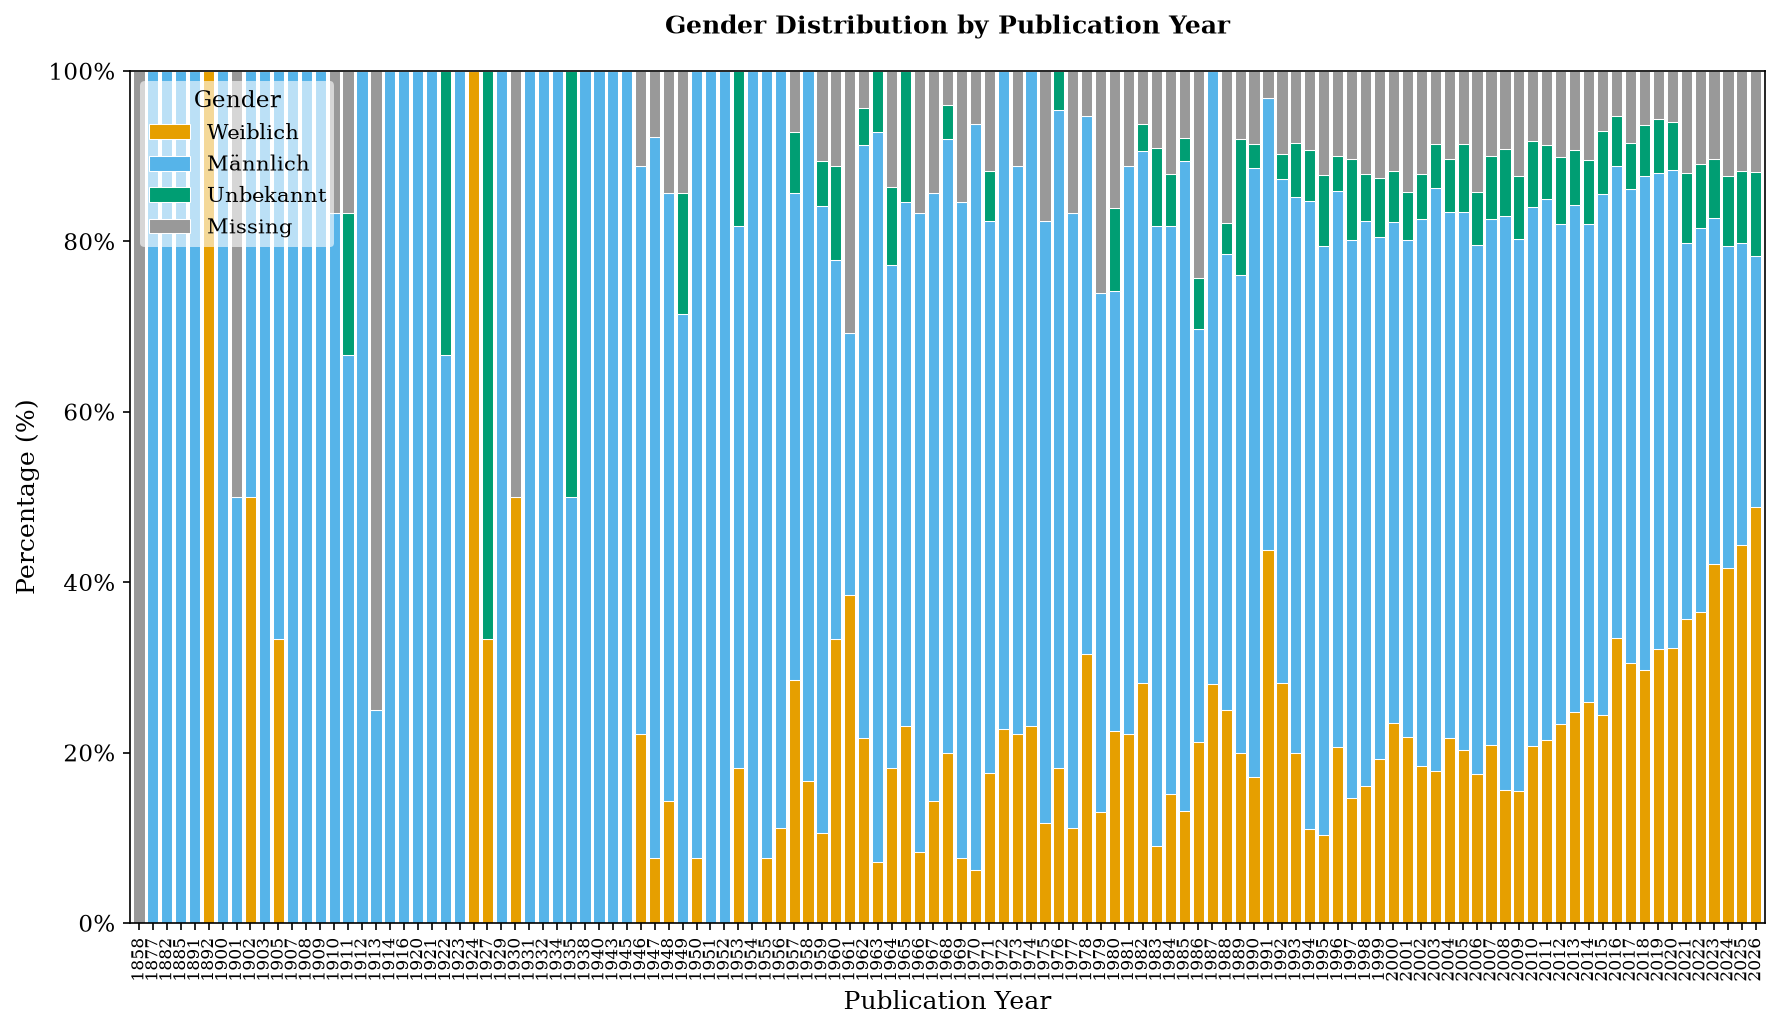

In [97]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Prepare data
data = df[["publication_date", "Geschlecht"]].copy()

data = data[
    (data["publication_date"] != 7519)
]

data["publication_date"] = pd.to_numeric(
    data["publication_date"], errors="coerce"
)
data["Geschlecht"] = data["Geschlecht"].fillna("Missing")

data = data.dropna(subset=["publication_date"])
data["publication_date"] = data["publication_date"].astype(int)

# Count each gender per year
counts = pd.crosstab(
    data["publication_date"],
    data["Geschlecht"]
).sort_index()

# Calculate percentages
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

# Order categories from bottom to top
preferred_order = ["Weiblich", "Männlich", "Unbekannt", "Missing"]

column_order = [
    col for col in preferred_order
    if col in percentages.columns
]

# Include any other categories not listed above
column_order += [
    col for col in percentages.columns
    if col not in column_order
]

percentages = percentages[column_order]

# Academic color palette
palette = {
    "Weiblich": "#E69F00",    # Orange
    "Männlich": "#56B4E9",    # Sky blue
    "Unbekannt": "#009E73",   # Bluish green
    "Missing": "#999999"     # Grey
}

# Match colors to the reordered categories
colors = [
    palette.get(gender, "#B56576")
    for gender in percentages.columns
]

# Plot styling
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

fig, ax = plt.subplots(figsize=(12, 7), facecolor="white")

percentages.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=colors,
    width=0.8,
    edgecolor="white",
    linewidth=0.5
)

# Format axes
ax.set_title(
    "Gender Distribution by Publication Year",
    fontsize=12,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Publication Year", fontsize=12)
ax.set_ylabel("Percentage (%)", fontsize=12)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(100))

ax.tick_params(axis="x", labelsize=8)

ax.legend(
    title="Gender",
    loc="upper left",
    frameon=True,
    facecolor="white",
    framealpha=0.6,
    edgecolor="none",
    fontsize=10,
    title_fontsize=11
)

plt.tight_layout()
# Save high-resolution PNG and vector PDF
plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/gender_by_year.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/gender_by_year.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

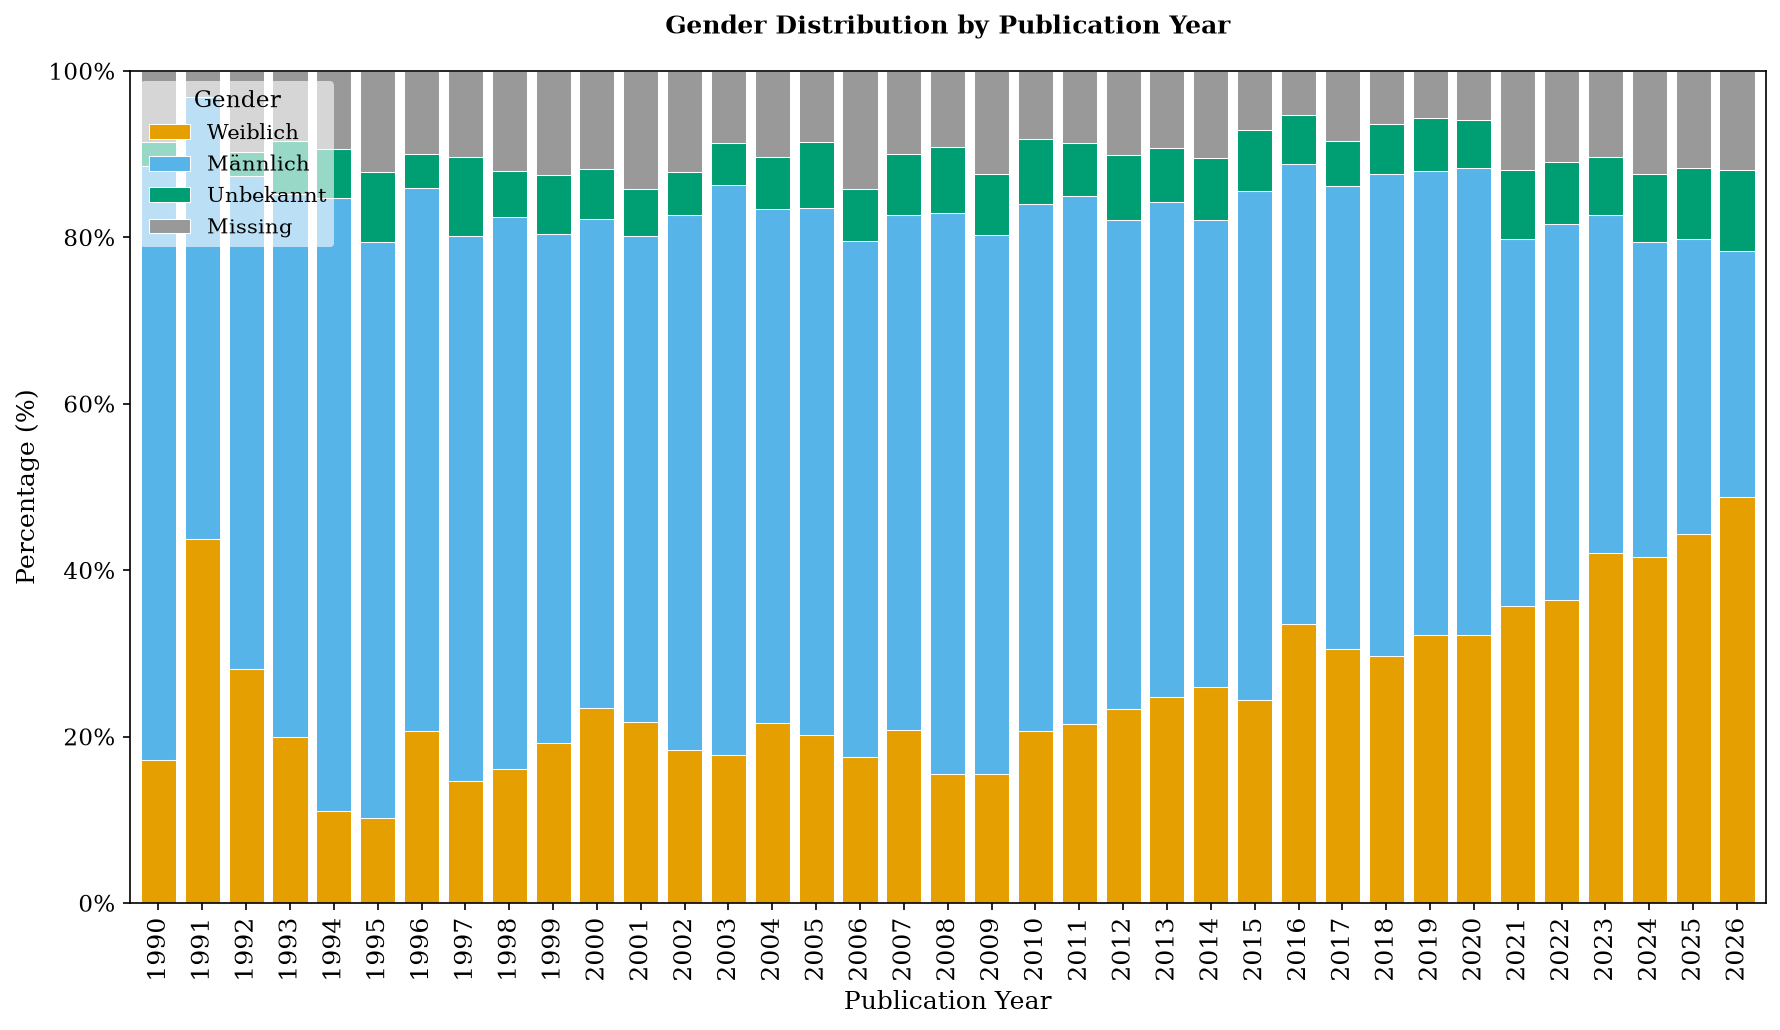

In [98]:
# filter df for entries after 1990
data = df[["publication_date", "Geschlecht"]].copy()

data["publication_date"] = pd.to_numeric(
    data["publication_date"], errors="coerce"
)
data["Geschlecht"] = data["Geschlecht"].fillna("Missing")

data = data.dropna(subset=["publication_date"])
data["publication_date"] = data["publication_date"].astype(int)

# Filter publication years after 1990
data = data[
    (data["publication_date"] > 1989) &
    (data["publication_date"] != 7519)
]

# Count each gender per year
counts = pd.crosstab(
    data["publication_date"],
    data["Geschlecht"]
).sort_index()

# Calculate percentages
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

# Order categories from bottom to top
preferred_order = ["Weiblich", "Männlich", "Unbekannt", "Missing"]

column_order = [
    col for col in preferred_order
    if col in percentages.columns
]

# Include any other categories not listed above
column_order += [
    col for col in percentages.columns
    if col not in column_order
]

percentages = percentages[column_order]

# Academic color palette
palette = {
    "Weiblich": "#E69F00",    # Orange
    "Männlich": "#56B4E9",    # Sky blue
    "Unbekannt": "#009E73",   # Bluish green
    "Missing": "#999999"     # Grey
}

# Match colors to the reordered categories
colors = [
    palette.get(gender, "#B56576")
    for gender in percentages.columns
]

# Plot styling
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

fig, ax = plt.subplots(figsize=(12, 7), facecolor="white")

percentages.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=colors,
    width=0.8,
    edgecolor="white",
    linewidth=0.5
)

# Format axes
ax.set_title(
    "Gender Distribution by Publication Year",
    fontsize=12,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Publication Year", fontsize=12)
ax.set_ylabel("Percentage (%)", fontsize=12)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(100))

ax.tick_params(axis="x", labelsize=12)

ax.legend(
    title="Gender",
    loc="upper left",
    frameon=True,
    facecolor="white",
    framealpha=0.6,
    edgecolor="none",
    fontsize=10,
    title_fontsize=11
)

plt.tight_layout()
# Save high-resolution PNG and vector PDF
plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/gender_by_year_after1989.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/gender_by_year_after1989.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [99]:
##Most translated authors

# Adjust these names to match your dataframe
author_col = "author"
title_col = "title"
language_col = "language"

# Keep female authors only
female_translations = df.loc[
    df["Geschlecht"].eq("Weiblich")
].copy()

# Remove rows without an author name
female_translations = female_translations.dropna(subset=[author_col])

# Optional: standardise text values before counting
for col in [author_col, title_col, language_col]:
    female_translations[col] = (
        female_translations[col]
        .astype("string")
        .str.strip()
    )

# Treat empty strings as missing values
female_translations[[title_col, language_col]] = (
    female_translations[[title_col, language_col]]
    .replace("", pd.NA)
)

# One row per female author:
# - number of unique translated titles
# - number of unique translation languages
female_author_table = (
    female_translations
    .groupby(author_col, dropna=False)
    .agg(
        translated_titles=(title_col, "nunique"),
        translated_languages=(language_col, "nunique")
    )
    .reset_index()
    .sort_values(
        by=["translated_titles", "translated_languages"],
        ascending=False
    )
)

# Rename columns for a publication-ready table
female_author_table = female_author_table.rename(
    columns={
        author_col: "Female author",
        "translated_titles": "Number of translated titles",
        "translated_languages": "Number of translation languages"
    }
)
#include which languages
female_author_table = (
    female_translations
    .groupby(author_col)
    .agg(
        translated_titles=(title_col, "nunique"),
        translated_languages=(language_col, "nunique"),
        languages=(
            language_col,
            lambda x: ", ".join(sorted(x.dropna().unique()))
        )
    )
    .reset_index()
    .sort_values(
        by=["translated_titles", "translated_languages"],
        ascending=False
    )
)

display(female_author_table)

female_author_table.to_csv(
    "/Users/lisateichmann/Desktop/ONB_gender/results/female_authors_translations.csv",
    index=False,
    encoding="utf-8-sig"
)

,author,translated_titles,translated_languages,languages
781,"Nöstlinger, Christine",369,34,"arm, bos, bul, cat, cat | ger, chi, cze, eng, ..."
655,"Luhn, Usch",220,14,"ara, bul, cze, dan, ger, heb, hun, ita, rum, s..."
476,"Jelinek, Elfriede",205,34,"alb, bos, bul, cat, chi, cze, dan, dut, eng, e..."
845,"Poznanski, Ursula",89,24,"che, cze, dan, dut, eng, est, fin, fre, ger, g..."
60,"Bachmann, Ingeborg",87,37,"arm, baq, baq | ger, cat, chi, cze, dan, dut, ..."
...,...,...,...,...
1207,"Åsbrink, Elisabeth",1,1,eng
1208,"Çakır, Seher",1,1,mul
1210,"Štefan, Anja",1,1,ger
1211,"Žic, Ivna",1,1,ger


In [100]:
##Look at the top 10
top10_female_authors = (
    female_author_table
    .nlargest(10, "translated_titles")
    .sort_values("translated_titles", ascending=True)
)

display(top10_female_authors)

,author,translated_titles,translated_languages,languages
403,"Haushofer, Marlen",59,25,"arm, baq, cat, dan, dut, dut | ger, eng, est, ..."
491,"Kaiblinger, Sonja",59,10,"cze, dan, dut, est, fin, ger, hun, ita, slo, spa"
1168,"Weninger, Brigitte",64,10,"cze, dut, eng, fin, fre, ger, ger | eng, hun, ..."
113,"Bohatta, Ida",66,2,"ger, hun"
709,"Mayröcker, Friederike",86,20,"bul, cze, dan, dut, eng, eng | ger, fre, ger, ..."
60,"Bachmann, Ingeborg",87,37,"arm, baq, baq | ger, cat, chi, cze, dan, dut, ..."
845,"Poznanski, Ursula",89,24,"che, cze, dan, dut, eng, est, fin, fre, ger, g..."
476,"Jelinek, Elfriede",205,34,"alb, bos, bul, cat, chi, cze, dan, dut, eng, e..."
655,"Luhn, Usch",220,14,"ara, bul, cze, dan, ger, heb, hun, ita, rum, s..."
781,"Nöstlinger, Christine",369,34,"arm, bos, bul, cat, cat | ger, chi, cze, eng, ..."


In [101]:
from adjustText import adjust_text

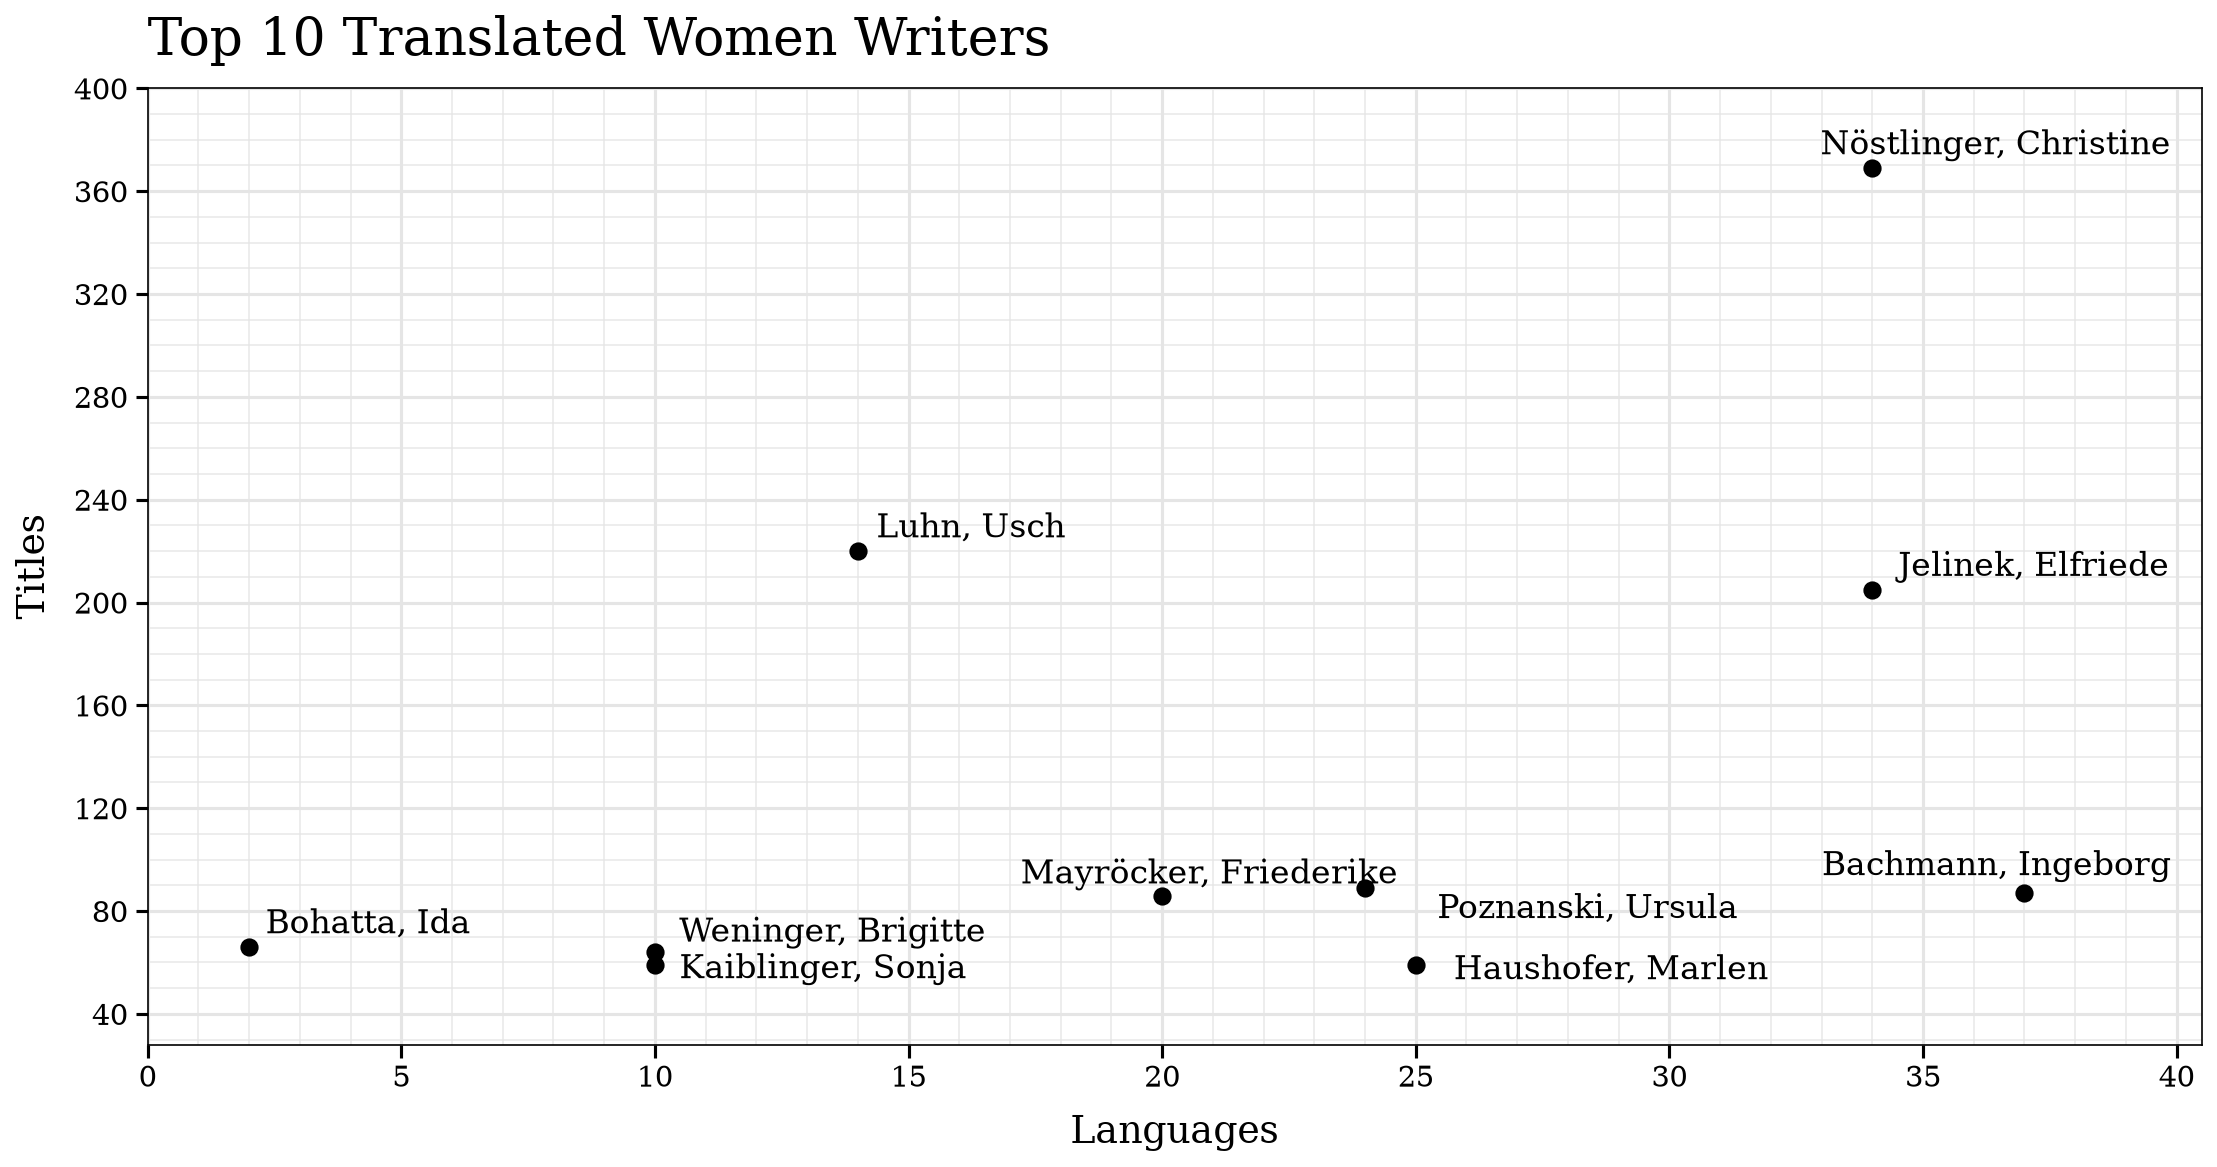

In [108]:
from matplotlib.ticker import MaxNLocator


# ------------------------------------------------------------
# 2. Plot style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

fig, ax = plt.subplots(
    figsize=(15, 8),
    facecolor="white"
)

# ------------------------------------------------------------
# 3. Draw scatter points
# ------------------------------------------------------------

ax.scatter(
    top10_female_authors["translated_languages"],
    top10_female_authors["translated_titles"],
    color="black",
    s=60,
    zorder=3
)

# ------------------------------------------------------------
# 4. Labels: automatically adjusted to reduce overlap
# ------------------------------------------------------------

texts = []

for _, row in top10_female_authors.iterrows():
    texts.append(
        ax.text(
            row["translated_languages"],
            row["translated_titles"],
            row["author"],
            fontsize=16,
            color="black",
            ha="left",
            va="bottom"
        )
    )

# ------------------------------------------------------------
# 5. Title and axis labels
# ------------------------------------------------------------

ax.set_title(
    "Top 10 Translated Women Writers",
    fontsize=25,
    fontweight="normal",
    loc="left",
    pad=16
)

ax.set_xlabel(
    "Languages",
    fontsize=18,
    labelpad=10
)

ax.set_ylabel(
    "Titles",
    fontsize=18,
    labelpad=10
)

# ------------------------------------------------------------
# 6. Axis limits and ticks
# ------------------------------------------------------------

x_min = top10_female_authors["translated_languages"].min()
x_max = top10_female_authors["translated_languages"].max()

y_min = top10_female_authors["translated_titles"].min()
y_max = top10_female_authors["translated_titles"].max()

# Add space around the outermost data points for labels
x_padding = max(1, (x_max - x_min) * 0.10)
y_padding = max(5, (y_max - y_min) * 0.10)

ax.set_xlim(
    max(0, x_min - x_padding),
    x_max + x_padding
)

ax.set_ylim(
    max(0, y_min - y_padding),
    y_max + y_padding
)

# Use integer tick values
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

# ------------------------------------------------------------
# 7. Grid and tick formatting
# ------------------------------------------------------------

ax.set_axisbelow(True)

# Major gridlines
ax.grid(
    which="major",
    color="#E5E5E5",
    linewidth=1.5
)

# Minor gridlines, similar to your example
ax.minorticks_on()

ax.grid(
    which="minor",
    color="#E5E5E5",
    linewidth=0.8,
    alpha=0.8
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=14,
    width=1.5,
    length=6
)

# Hide minor tick marks but retain minor gridlines
ax.tick_params(
    axis="both",
    which="minor",
    length=0
)

# ------------------------------------------------------------
# 8. Move labels to avoid overlaps
# ------------------------------------------------------------

adjust_text(
    texts,
    ax=ax,
    expand_points=(1.05, 1.05),
    expand_text=(1.02, 1.05),
    force_points=(0.1, 0.15),
    force_text=(0.15, 0.2),
    force_pull=(1.0, 1.2),
    max_move=(15, 10)
    )


# ------------------------------------------------------------
# 9. Save and show
# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/top10_translated_women_writers_scatter.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/top10_translated_women_writers_scatter.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

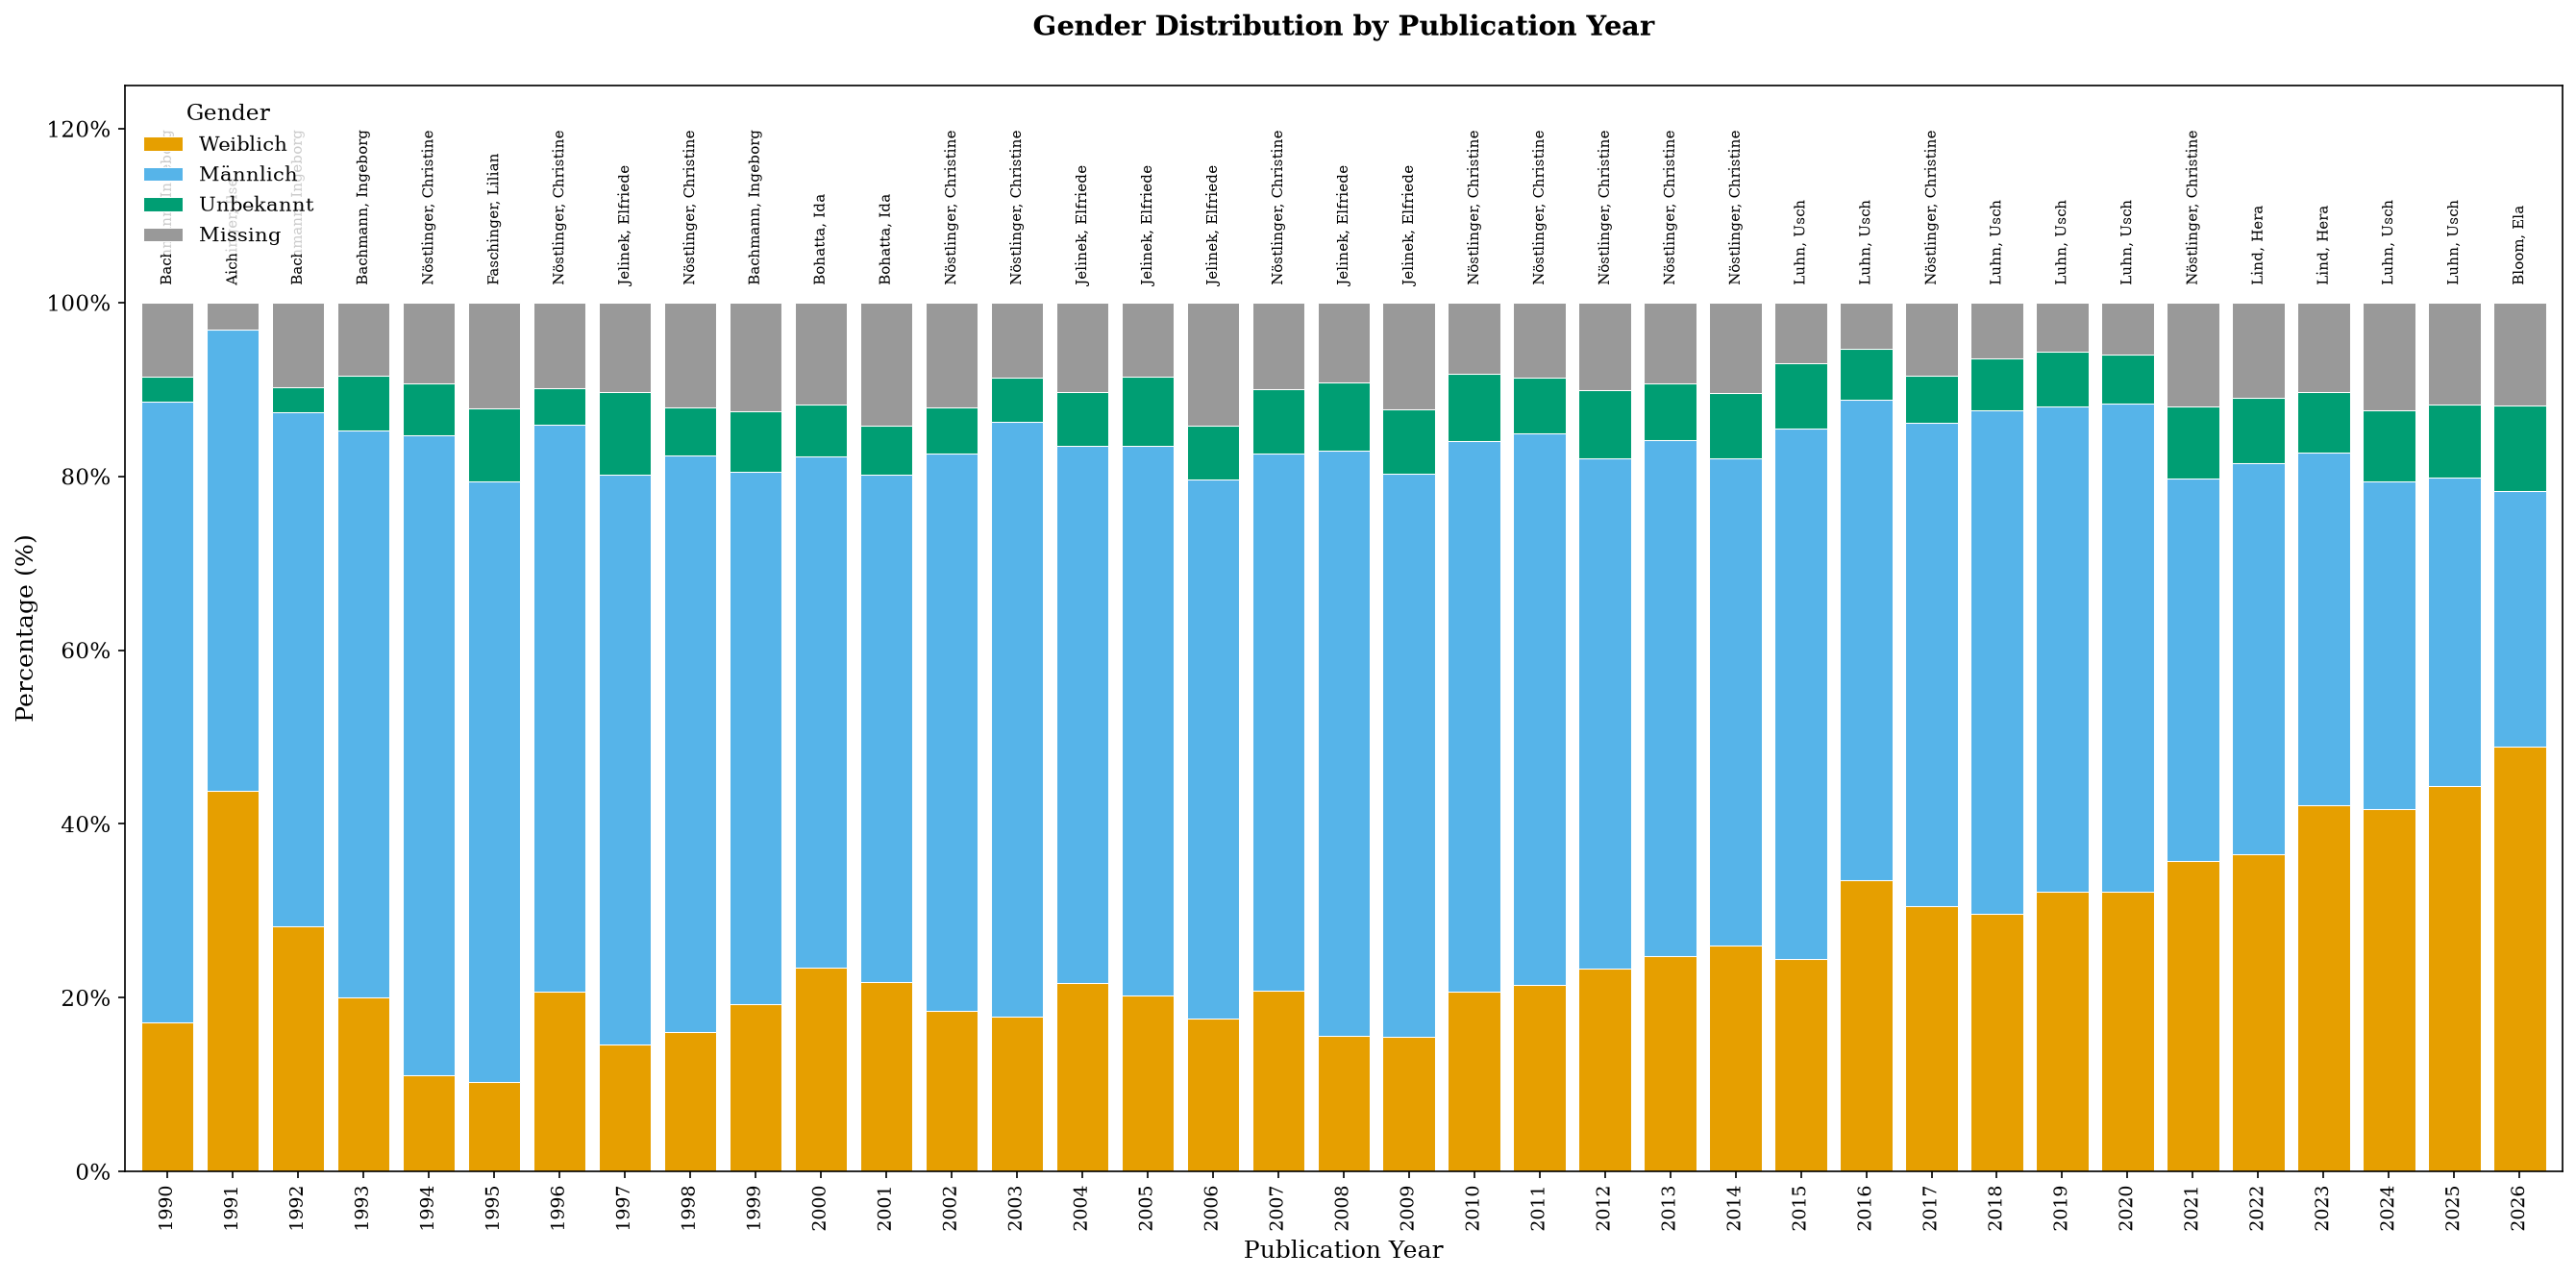

In [109]:
##Most translated author per year
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------
# 1. Keep and clean the needed columns
# ------------------------------------------------------------

data = df[
    [
        "publication_date",
        "Geschlecht",
        "author",
        "title"
    ]
].copy()

# Convert publication year to numeric
data["publication_date"] = pd.to_numeric(
    data["publication_date"],
    errors="coerce"
)

# Replace missing gender information
data["Geschlecht"] = data["Geschlecht"].fillna("Missing")

# Remove rows without a usable publication year
data = data.dropna(subset=["publication_date"])
data["publication_date"] = data["publication_date"].astype(int)

# Keep years from 1990 onward and remove invalid year
data = data[
    (data["publication_date"] > 1989) &
    (data["publication_date"] != 7519)
].copy()


# ------------------------------------------------------------
# 2. Calculate the top female author for each publication year
# ------------------------------------------------------------

# Keep female-author records only
female_data = data.loc[
    data["Geschlecht"].eq("Weiblich")
].copy()

# Clean author names and titles
female_data["author"] = (
    female_data["author"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

female_data["title"] = (
    female_data["title"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Only retain rows with author and title information
female_data = female_data.dropna(
    subset=["publication_date", "author", "title"]
)

# Count distinct titles per female author per publication year
female_author_year_counts = (
    female_data
    .groupby(["publication_date", "author"])["title"]
    .nunique()
    .reset_index(name="translated_titles")
)

# Sort so the author with the highest title count comes first.
# If there is a tie, choose the alphabetically first author.
female_author_year_counts = female_author_year_counts.sort_values(
    by=["publication_date", "translated_titles", "author"],
    ascending=[True, False, True]
)

# Keep only one leading female author for every year
top_female_author_by_year = (
    female_author_year_counts
    .drop_duplicates(subset="publication_date", keep="first")
    .set_index("publication_date")
)


# ------------------------------------------------------------
# 3. Calculate gender percentages per publication year
# ------------------------------------------------------------

counts = pd.crosstab(
    data["publication_date"],
    data["Geschlecht"]
).sort_index()

percentages = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

# Match female-author labels to the exact year order in the plot
top_female_labels = (
    top_female_author_by_year["author"]
    .reindex(percentages.index)
)


# ------------------------------------------------------------
# 4. Order gender categories and assign colours
# ------------------------------------------------------------

preferred_order = ["Weiblich", "Männlich", "Unbekannt", "Missing"]

column_order = [
    col for col in preferred_order
    if col in percentages.columns
]

# Include any unexpected gender categories as well
column_order += [
    col for col in percentages.columns
    if col not in column_order
]

percentages = percentages[column_order]

palette = {
    "Weiblich": "#E69F00",   # Orange
    "Männlich": "#56B4E9",   # Sky blue
    "Unbekannt": "#009E73",  # Green
    "Missing": "#999999"     # Grey
}

colors = [
    palette.get(gender, "#B56576")
    for gender in percentages.columns
]


# ------------------------------------------------------------
# 5. Create the stacked bar chart
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

# Make the figure wider because there may be many annual bars
fig, ax = plt.subplots(
    figsize=(18, 9),
    facecolor="white"
)

percentages.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=colors,
    width=0.8,
    edgecolor="white",
    linewidth=0.5
)


# ------------------------------------------------------------
# 6. Add the top female author name above each year bar
# ------------------------------------------------------------

for x_position, author in enumerate(top_female_labels):

    # Some years may contain no female author with title information
    if pd.notna(author):
        ax.text(
            x=x_position,
            y=102,
            s=str(author),
            ha="center",
            va="bottom",
            rotation=90,
            fontsize=7,
            color="black",
            clip_on=False
        )


# ------------------------------------------------------------
# 7. Format axes and legend
# ------------------------------------------------------------

ax.set_title(
    "Gender Distribution by Publication Year",
    fontsize=14,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Publication Year", fontsize=12)
ax.set_ylabel("Percentage (%)", fontsize=12)

# Bars remain 100%; space above is for author-name labels.
ax.set_ylim(0, 125)

ax.yaxis.set_major_formatter(PercentFormatter(100))

# Rotating years helps if your data cover many years
ax.tick_params(
    axis="x",
    labelsize=9,
    rotation=90
)

ax.legend(
    title="Gender",
    loc="upper left",
    frameon=True,
    facecolor="white",
    framealpha=0.8,
    edgecolor="none",
    fontsize=10,
    title_fontsize=11
)

plt.tight_layout()

# ------------------------------------------------------------
# 8. Save and display the plot
# ------------------------------------------------------------

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/gender_by_year_top_female_author.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/gender_by_year_top_female_author.pdf",
    bbox_inches="tight",
    facecolor="white"
)

# This is what displays the figure in the VS Code notebook:
plt.show()

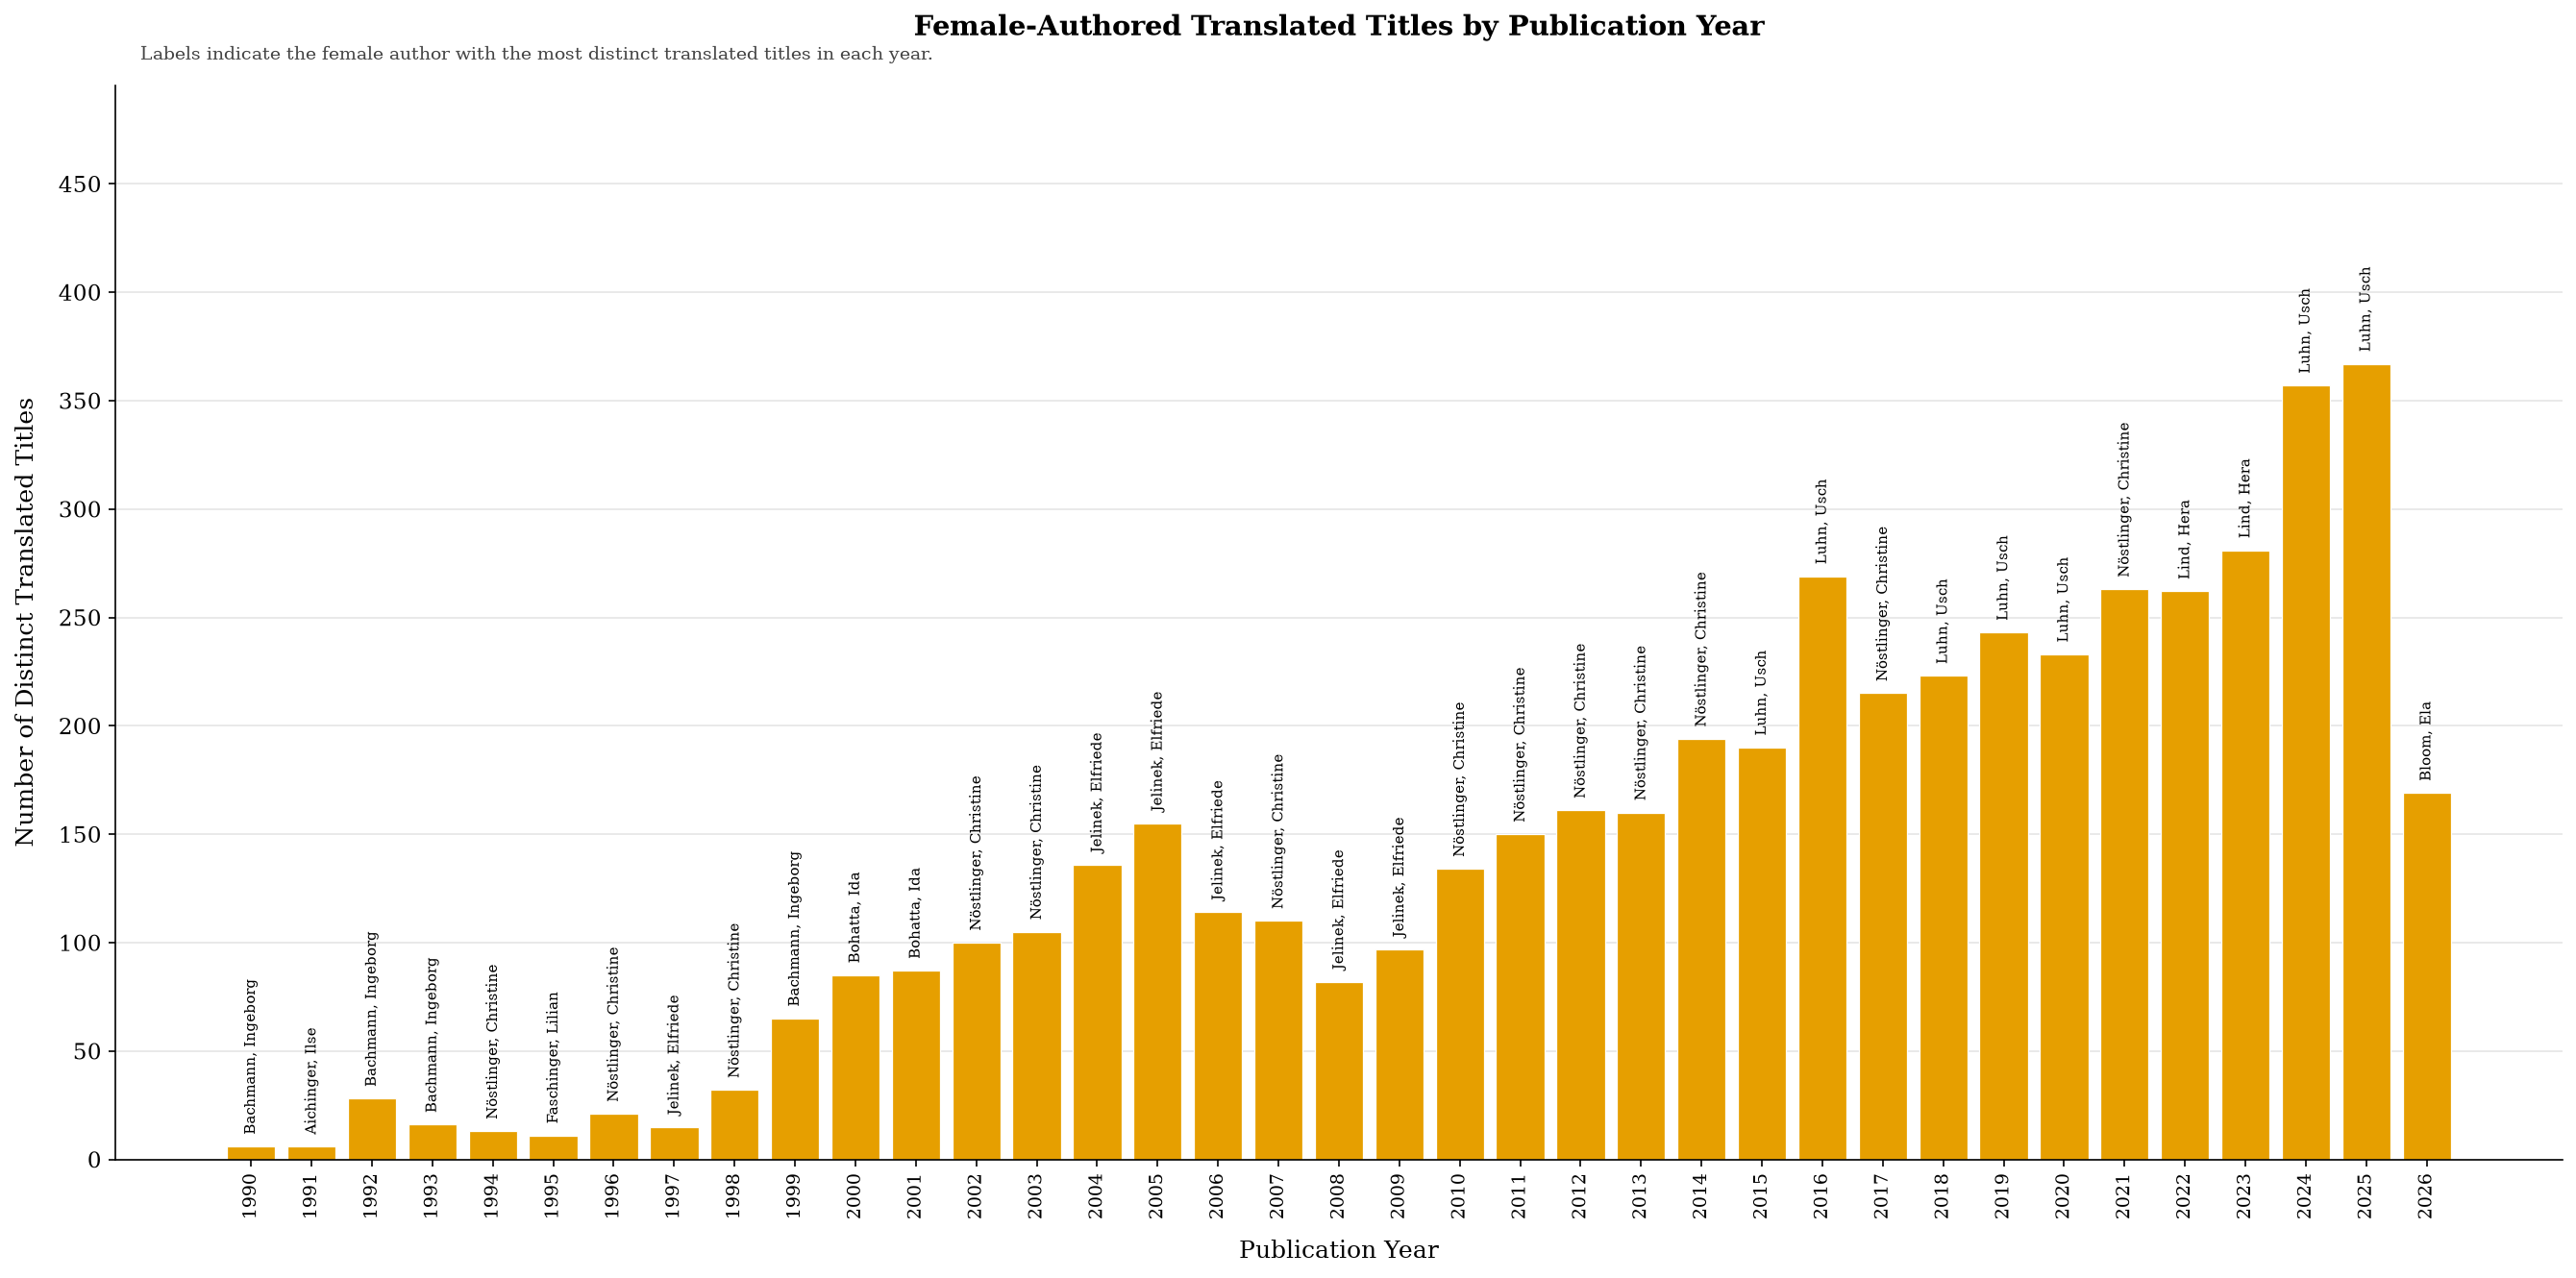

In [110]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# ------------------------------------------------------------
# 1. Keep needed columns and clean publication years
# ------------------------------------------------------------

data = df[
    [
        "publication_date",
        "Geschlecht",
        "author",
        "title"
    ]
].copy()

data["publication_date"] = pd.to_numeric(
    data["publication_date"],
    errors="coerce"
)

data = data.dropna(subset=["publication_date"])
data["publication_date"] = data["publication_date"].astype(int)

# Keep years from 1990 onward and remove invalid year
data = data[
    (data["publication_date"] > 1989) &
    (data["publication_date"] != 7519)
].copy()

# ------------------------------------------------------------
# 2. KEEP FEMALE AUTHORS ONLY
# ------------------------------------------------------------

female_data = data.loc[
    data["Geschlecht"].eq("Weiblich")
].copy()

# Clean author and title values
female_data["author"] = (
    female_data["author"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

female_data["title"] = (
    female_data["title"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Retain records with author and title information
female_data = female_data.dropna(
    subset=["author", "title"]
)

# ------------------------------------------------------------
# 3. Count distinct female-authored titles per year
# ------------------------------------------------------------

female_titles_by_year = (
    female_data
    .groupby("publication_date")["title"]
    .nunique()
    .sort_index()
)

# ------------------------------------------------------------
# 4. Find the female author with the most titles per year
# ------------------------------------------------------------

female_author_year_counts = (
    female_data
    .groupby(["publication_date", "author"])["title"]
    .nunique()
    .reset_index(name="translated_titles")
)

# Sort by:
# 1. publication year;
# 2. number of titles, descending;
# 3. author alphabetically, to resolve ties consistently.
female_author_year_counts = female_author_year_counts.sort_values(
    by=["publication_date", "translated_titles", "author"],
    ascending=[True, False, True]
)

# Retain the author with the highest number of titles in each year
top_female_author_by_year = (
    female_author_year_counts
    .drop_duplicates(subset="publication_date", keep="first")
    .set_index("publication_date")
)

# Align author labels to the year order in the bar chart
top_female_labels = (
    top_female_author_by_year["author"]
    .reindex(female_titles_by_year.index)
)

# ------------------------------------------------------------
# 5. Plot styling
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

fig, ax = plt.subplots(
    figsize=(18, 9),
    facecolor="white"
)

# ------------------------------------------------------------
# 6. Draw annual bar chart
# ------------------------------------------------------------

bars = ax.bar(
    range(len(female_titles_by_year)),
    female_titles_by_year.values,
    color="#E69F00",       # orange = female category in your palette
    edgecolor="white",
    linewidth=0.6,
    width=0.8
)

# Use actual years as x-axis labels
ax.set_xticks(range(len(female_titles_by_year)))
ax.set_xticklabels(
    female_titles_by_year.index.astype(str),
    rotation=90,
    fontsize=9
)

# ------------------------------------------------------------
# 7. Label every bar with the leading female author
# ------------------------------------------------------------

max_titles = female_titles_by_year.max()

for x_position, (year, author) in enumerate(top_female_labels.items()):

    if pd.notna(author):
        bar_height = female_titles_by_year.loc[year]

        ax.text(
            x=x_position,
            y=bar_height + max_titles * 0.015,
            s=str(author),
            ha="center",
            va="bottom",
            rotation=90,
            fontsize=7,
            color="black",
            clip_on=False
        )

# ------------------------------------------------------------
# 8. Format chart
# ------------------------------------------------------------

ax.set_title(
    "Female-Authored Translated Titles by Publication Year",
    fontsize=14,
    fontweight="bold",
    pad=25
)

ax.set_xlabel(
    "Publication Year",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Number of Distinct Translated Titles",
    fontsize=12,
    labelpad=10
)

# Leave space above bars for vertical author names
ax.set_ylim(
    0,
    max_titles * 1.35
)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_axisbelow(True)
ax.grid(
    axis="y",
    color="#E5E5E5",
    linewidth=0.8
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Explain what labels mean
ax.text(
    0.01,
    1.02,
    "Labels indicate the female author with the most distinct translated titles in each year.",
    transform=ax.transAxes,
    fontsize=9,
    color="#444444",
    va="bottom"
)

plt.tight_layout()

# ------------------------------------------------------------
# 9. Save and display
# ------------------------------------------------------------

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/female_titles_by_year_top_author.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/female_titles_by_year_top_author.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Years highlighted in red for Nöstlinger, Christine:
[1994, 1996, 1998, 2002, 2003, 2007, 2010, 2011, 2012, 2013, 2014, 2017, 2021]


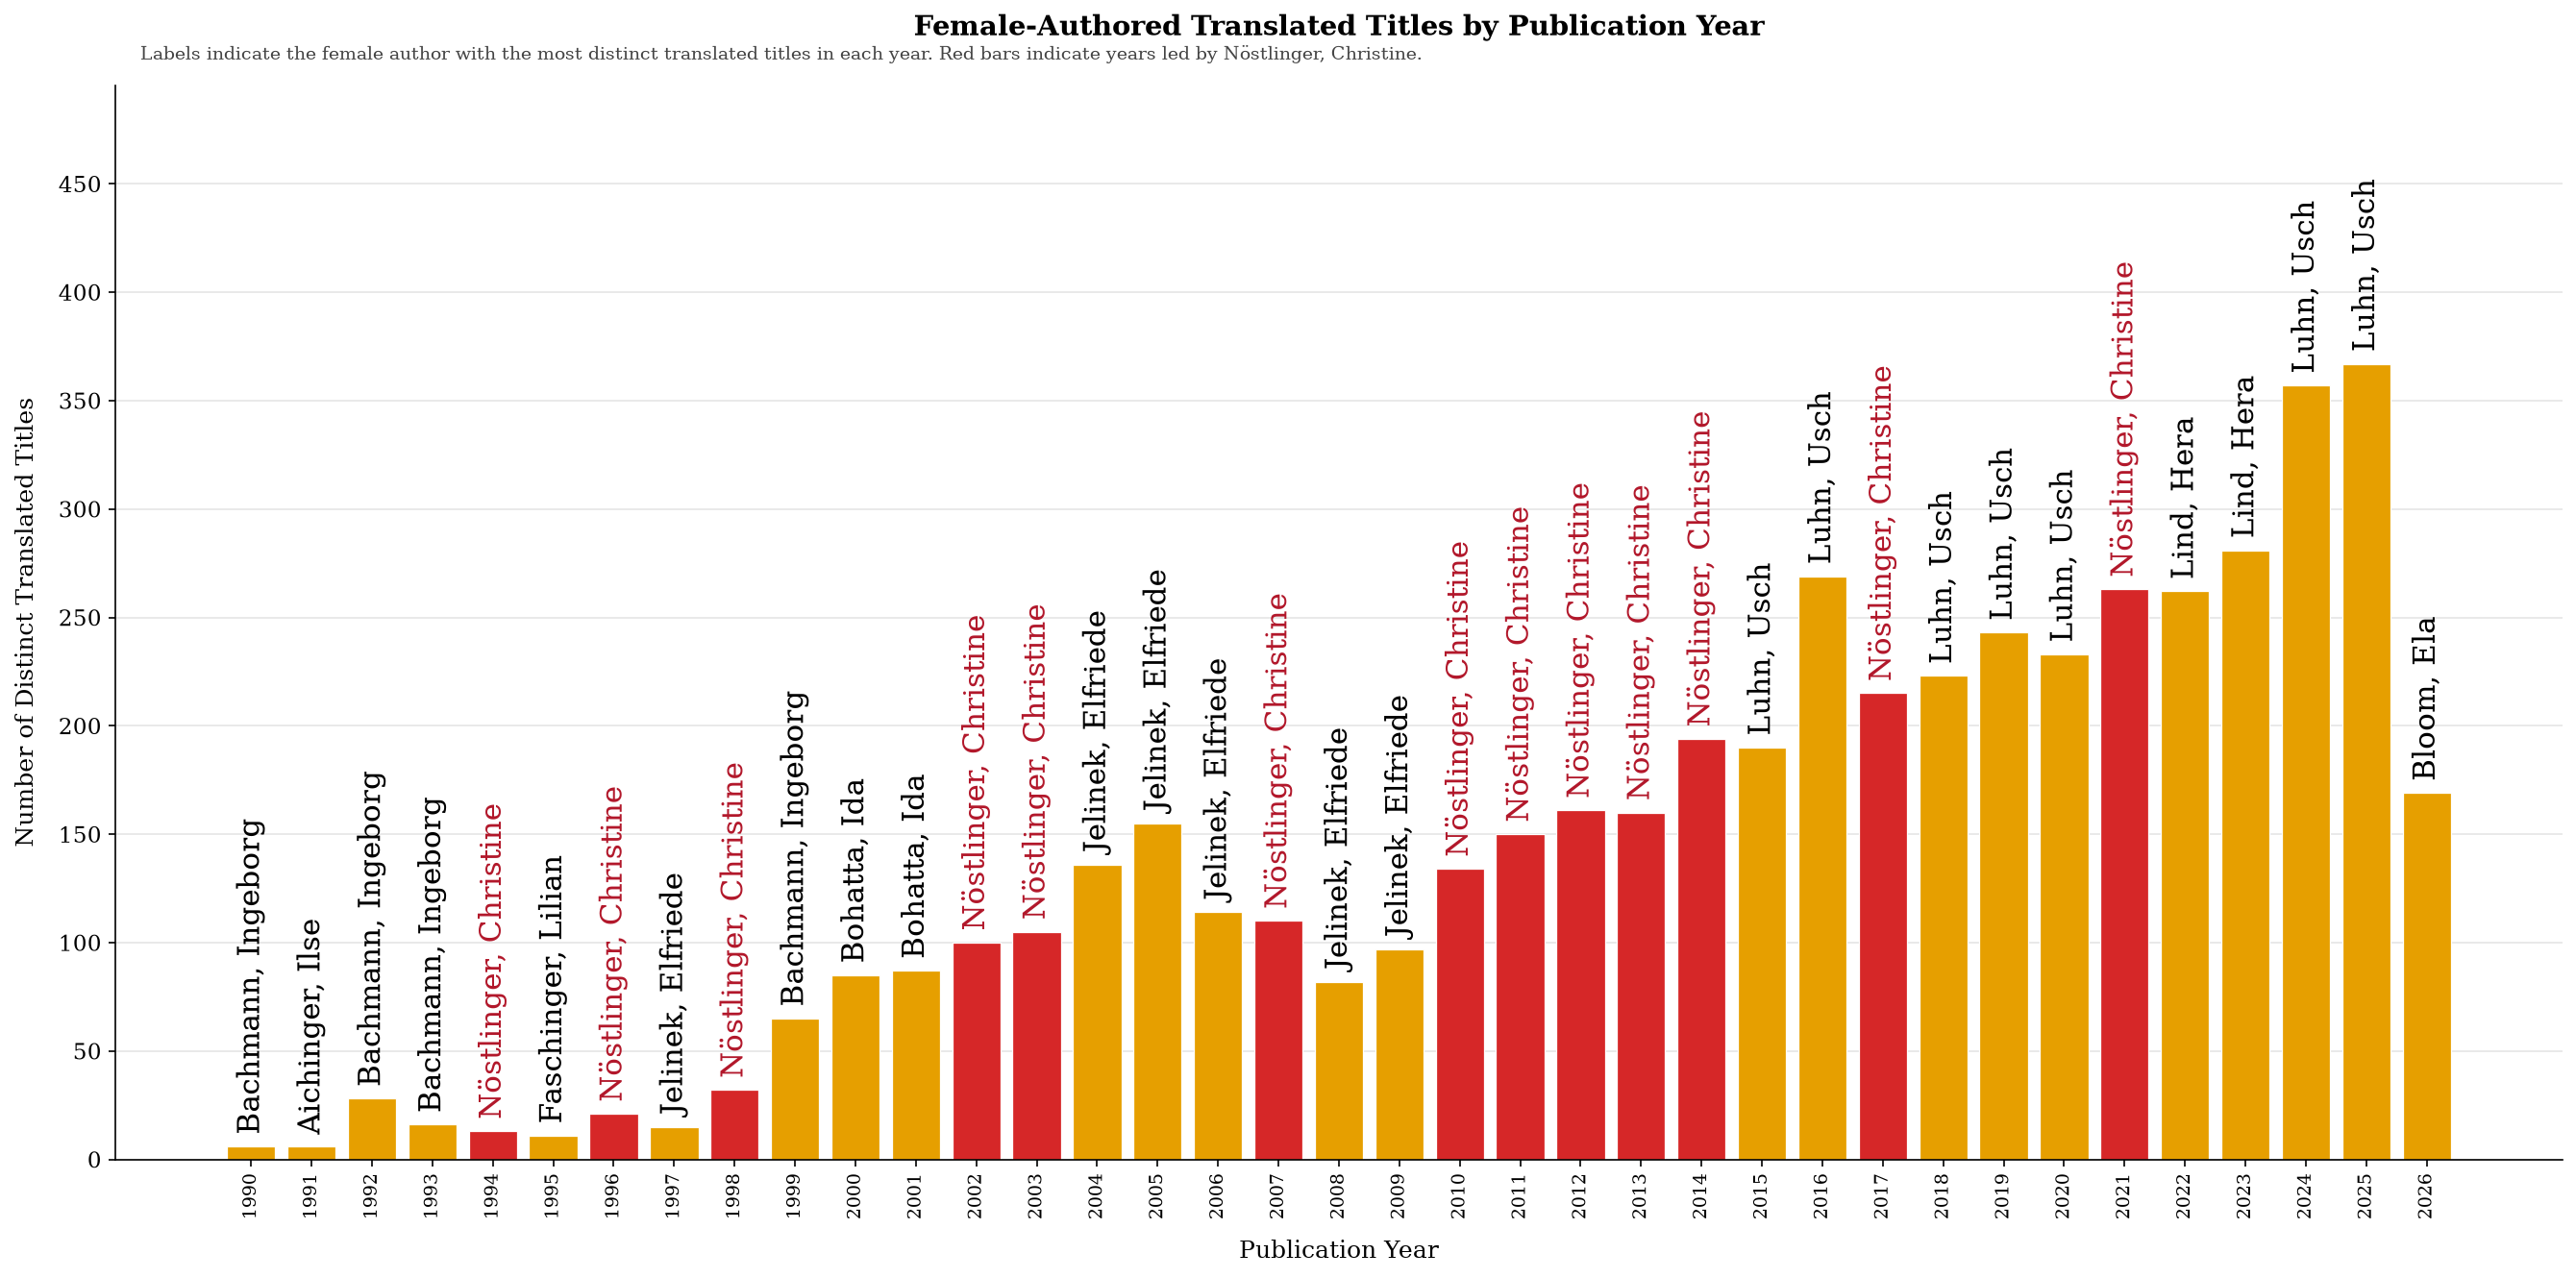

In [122]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# ------------------------------------------------------------
# 1. Keep needed columns and clean publication years
# ------------------------------------------------------------

data = df[
    [
        "publication_date",
        "Geschlecht",
        "author",
        "title"
    ]
].copy()

data["publication_date"] = pd.to_numeric(
    data["publication_date"],
    errors="coerce"
)

data = data.dropna(subset=["publication_date"])
data["publication_date"] = data["publication_date"].astype(int)

# Keep years from 1990 onward and remove invalid year
data = data[
    (data["publication_date"] > 1989) &
    (data["publication_date"] != 7519)
].copy()

# ------------------------------------------------------------
# 2. KEEP FEMALE AUTHORS ONLY
# ------------------------------------------------------------

female_data = data.loc[
    data["Geschlecht"].eq("Weiblich")
].copy()

# Clean author and title values
female_data["author"] = (
    female_data["author"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

female_data["title"] = (
    female_data["title"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Retain records with author and title information
female_data = female_data.dropna(
    subset=["author", "title"]
)

# ------------------------------------------------------------
# 3. Count distinct female-authored titles per year
# ------------------------------------------------------------

female_titles_by_year = (
    female_data
    .groupby("publication_date")["title"]
    .nunique()
    .sort_index()
)

# ------------------------------------------------------------
# 4. Find the female author with the most titles per year
# ------------------------------------------------------------

female_author_year_counts = (
    female_data
    .groupby(["publication_date", "author"])["title"]
    .nunique()
    .reset_index(name="translated_titles")
)

# Sort by:
# 1. publication year;
# 2. number of titles, descending;
# 3. author alphabetically, to resolve ties consistently.
female_author_year_counts = female_author_year_counts.sort_values(
    by=["publication_date", "translated_titles", "author"],
    ascending=[True, False, True]
)

# Retain the author with the highest number of titles in each year
top_female_author_by_year = (
    female_author_year_counts
    .drop_duplicates(subset="publication_date", keep="first")
    .set_index("publication_date")
)

# Align author labels to the year order in the bar chart
top_female_labels = (
    top_female_author_by_year["author"]
    .reindex(female_titles_by_year.index)
)

# ------------------------------------------------------------
# 5. Set colours:
#    red if Nöstlinger, Christine is the leading author;
#    orange for every other year
# ------------------------------------------------------------

is_noestlinger_year = top_female_labels.eq("Nöstlinger, Christine")

bar_colors = [
    "#D62728" if is_noestlinger else "#E69F00"
    for is_noestlinger in is_noestlinger_year
]

# Optional check: print the highlighted years
print("Years highlighted in red for Nöstlinger, Christine:")
print(female_titles_by_year.index[is_noestlinger_year].tolist())

# ------------------------------------------------------------
# 6. Plot styling
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

fig, ax = plt.subplots(
    figsize=(18, 9),
    facecolor="white"
)

# ------------------------------------------------------------
# 7. Draw annual bar chart
# ------------------------------------------------------------

bars = ax.bar(
    range(len(female_titles_by_year)),
    female_titles_by_year.values,
    color=bar_colors,       # red for Nöstlinger years; orange otherwise
    edgecolor="white",
    linewidth=0.6,
    width=0.8
)

# Use actual years as x-axis labels
ax.set_xticks(range(len(female_titles_by_year)))
ax.set_xticklabels(
    female_titles_by_year.index.astype(str),
    rotation=90,
    fontsize=9
)

# ------------------------------------------------------------
# 8. Label every bar with the leading female author
# ------------------------------------------------------------

max_titles = female_titles_by_year.max()

for x_position, (year, author) in enumerate(top_female_labels.items()):

    if pd.notna(author):
        bar_height = female_titles_by_year.loc[year]

        # Use red text for Nöstlinger labels and black for all others
        label_colour = (
            "#B2182B"
            if author == "Nöstlinger, Christine"
            else "black"
        )

        ax.text(
            x=x_position,
            y=bar_height + max_titles * 0.015,
            s=str(author),
            ha="center",
            va="bottom",
            rotation=90,
            fontsize=15,
            color=label_colour,
            clip_on=False
        )

# ------------------------------------------------------------
# 9. Format chart
# ------------------------------------------------------------

ax.set_title(
    "Female-Authored Translated Titles by Publication Year",
    fontsize=14,
    fontweight="bold",
    pad=25
)

ax.set_xlabel(
    "Publication Year",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Number of Distinct Translated Titles",
    fontsize=12,
    labelpad=10
)

# Leave space above bars for vertical author names
ax.set_ylim(
    0,
    max_titles * 1.35
)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_axisbelow(True)
ax.grid(
    axis="y",
    color="#E5E5E5",
    linewidth=0.8
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Explain what labels and red bars mean
ax.text(
    0.01,
    1.02,
    (
        "Labels indicate the female author with the most distinct translated "
        "titles in each year. Red bars indicate years led by Nöstlinger, Christine."
    ),
    transform=ax.transAxes,
    fontsize=9,
    color="#444444",
    va="bottom"
)

plt.tight_layout()

# ------------------------------------------------------------
# 10. Save and display
# ------------------------------------------------------------

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/"
    "female_titles_by_year_top_author_noestlinger_red.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "/Users/lisateichmann/Desktop/ONB_gender/results/"
    "female_titles_by_year_top_author_noestlinger_red.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [113]:
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. Keep only authors with gender recorded as "Unbekannt"
# ------------------------------------------------------------

unknown_gender_data = df.loc[
    df["Geschlecht"].eq("Unbekannt"),
    ["author", "language", "title", "publication_date"]
].copy()

# ------------------------------------------------------------
# 2. Clean text fields
# ------------------------------------------------------------

for column in ["author", "language", "title"]:
    unknown_gender_data[column] = (
        unknown_gender_data[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# Optional: remove rows with no language or title
unknown_gender_data = unknown_gender_data.dropna(
    subset=["language", "title"]
).copy()

# ------------------------------------------------------------
# 3. Language frequencies
# ------------------------------------------------------------

unknown_language_frequencies = (
    unknown_gender_data["language"]
    .value_counts(dropna=False)
    .rename_axis("language")
    .reset_index(name="frequency")
)

unknown_language_frequencies["percentage"] = (
    unknown_language_frequencies["frequency"]
    / unknown_language_frequencies["frequency"].sum()
    * 100
).round(2)

print("Language frequencies for authors with Geschlecht = 'Unbekannt':")
display(unknown_language_frequencies)

# ------------------------------------------------------------
# 4. Title frequencies
# ------------------------------------------------------------

unknown_title_frequencies = (
    unknown_gender_data["title"]
    .value_counts(dropna=False)
    .rename_axis("title")
    .reset_index(name="frequency")
)

print("Most frequent titles for authors with Geschlecht = 'Unbekannt':")
display(unknown_title_frequencies)

# ------------------------------------------------------------
# 5. Combined language + title frequency table
# ------------------------------------------------------------

unknown_language_title_frequencies = (
    unknown_gender_data
    .groupby(["language", "title"], dropna=False)
    .size()
    .reset_index(name="frequency")
    .sort_values(
        by=["frequency", "language", "title"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

print("Language and title frequencies for authors with Geschlecht = 'Unbekannt':")
display(unknown_language_title_frequencies)

# ------------------------------------------------------------
# 6. Optional: author frequencies as well
# ------------------------------------------------------------

unknown_author_frequencies = (
    unknown_gender_data["author"]
    .value_counts(dropna=False)
    .rename_axis("author")
    .reset_index(name="frequency")
)

print("Author frequencies for authors with Geschlecht = 'Unbekannt':")
display(unknown_author_frequencies)

# ------------------------------------------------------------
# 7. Save tables as CSV files
# ------------------------------------------------------------

output_folder = Path("/Users/lisateichmann/Desktop/ONB_gender/results")
output_folder.mkdir(parents=True, exist_ok=True)

unknown_language_frequencies.to_csv(
    output_folder / "unknown_gender_language_frequencies.csv",
    index=False,
    encoding="utf-8-sig"
)

unknown_title_frequencies.to_csv(
    output_folder / "unknown_gender_title_frequencies.csv",
    index=False,
    encoding="utf-8-sig"
)

unknown_language_title_frequencies.to_csv(
    output_folder / "unknown_gender_language_title_frequencies.csv",
    index=False,
    encoding="utf-8-sig"
)

unknown_author_frequencies.to_csv(
    output_folder / "unknown_gender_author_frequencies.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFiles saved in:")
print(output_folder)

Language frequencies for authors with Geschlecht = 'Unbekannt':


,language,frequency,percentage
0,ger,1610,72.88
1,eng,105,4.75
2,fre,81,3.67
3,cze,46,2.08
4,ita,38,1.72
...,...,...,...
70,ger | eng,1,0.05
71,chi | eng,1,0.05
72,mon | eng,1,0.05
73,fre | ger,1,0.05


Most frequent titles for authors with Geschlecht = 'Unbekannt':


,title,frequency
0,Odes to aseity,12
1,Totenfrau : Thriller,12
2,Girl crush,6
3,<<A>> journey round the world : poems,5
4,Max und Micha : die Junior-Detektive vom Wolfg...,5
...,...,...
1304,Written on the edge,1
1305,<<Die>> Wüste : Roman,1
1306,Z milosti těla,1
1307,Z'soummgebunt'n za an' grouß'n Strauß : = Zusa...,1


Language and title frequencies for authors with Geschlecht = 'Unbekannt':


,language,title,frequency
0,ger,Totenfrau : Thriller,12
1,eng,Odes to aseity,10
2,ger,Girl crush,6
3,ger,Max und Micha : die Junior-Detektive vom Wolfg...,5
4,eng,Woman of the dead : a thriller,4
...,...,...,...
1309,srp,"Oups - Ljubav, ah, ljubav",1
1310,srp,Tumači slobode : epigrami,1
1311,tur,Friedrich Ch. Zauner'in romanlarında ilişki kr...,1
1312,ukr,Maty-stradnycja,1


Author frequencies for authors with Geschlecht = 'Unbekannt':


,author,frequency
0,"Svatek, Kurt F.",159
1,"Aichner, Bernhard",98
2,"Summer, Drea",30
3,"Reichl, Eva",30
4,"Bauer, Hermann",30
...,...,...
655,"Ćwierk, Konstanty",1
656,"Bertalan, Doris",1
657,"Margoshes, Joseph",1
658,"Allitsch-Tiefenbacher, Valerie",1



Files saved in:
/Users/lisateichmann/Desktop/ONB_gender/results


Top author with Geschlecht = 'Unbekannt' in each publication year:


,year,distinct_titles_in_year,top_author
0,1990,1,"Klawatsch, Hans"
1,1992,3,"Masoner, Gottfried"
2,1993,6,"Kaser, Norbert C."
3,1994,7,"Svatek, Kurt F."
4,1995,9,"Svatek, Kurt F."
5,1996,5,"Clément, Catherine"
6,1997,11,"Svatek, Kurt F."
7,1998,11,"Svatek, Kurt F."
8,1999,24,"Detela, Lev"
9,2000,22,"Rinner, Klaus"


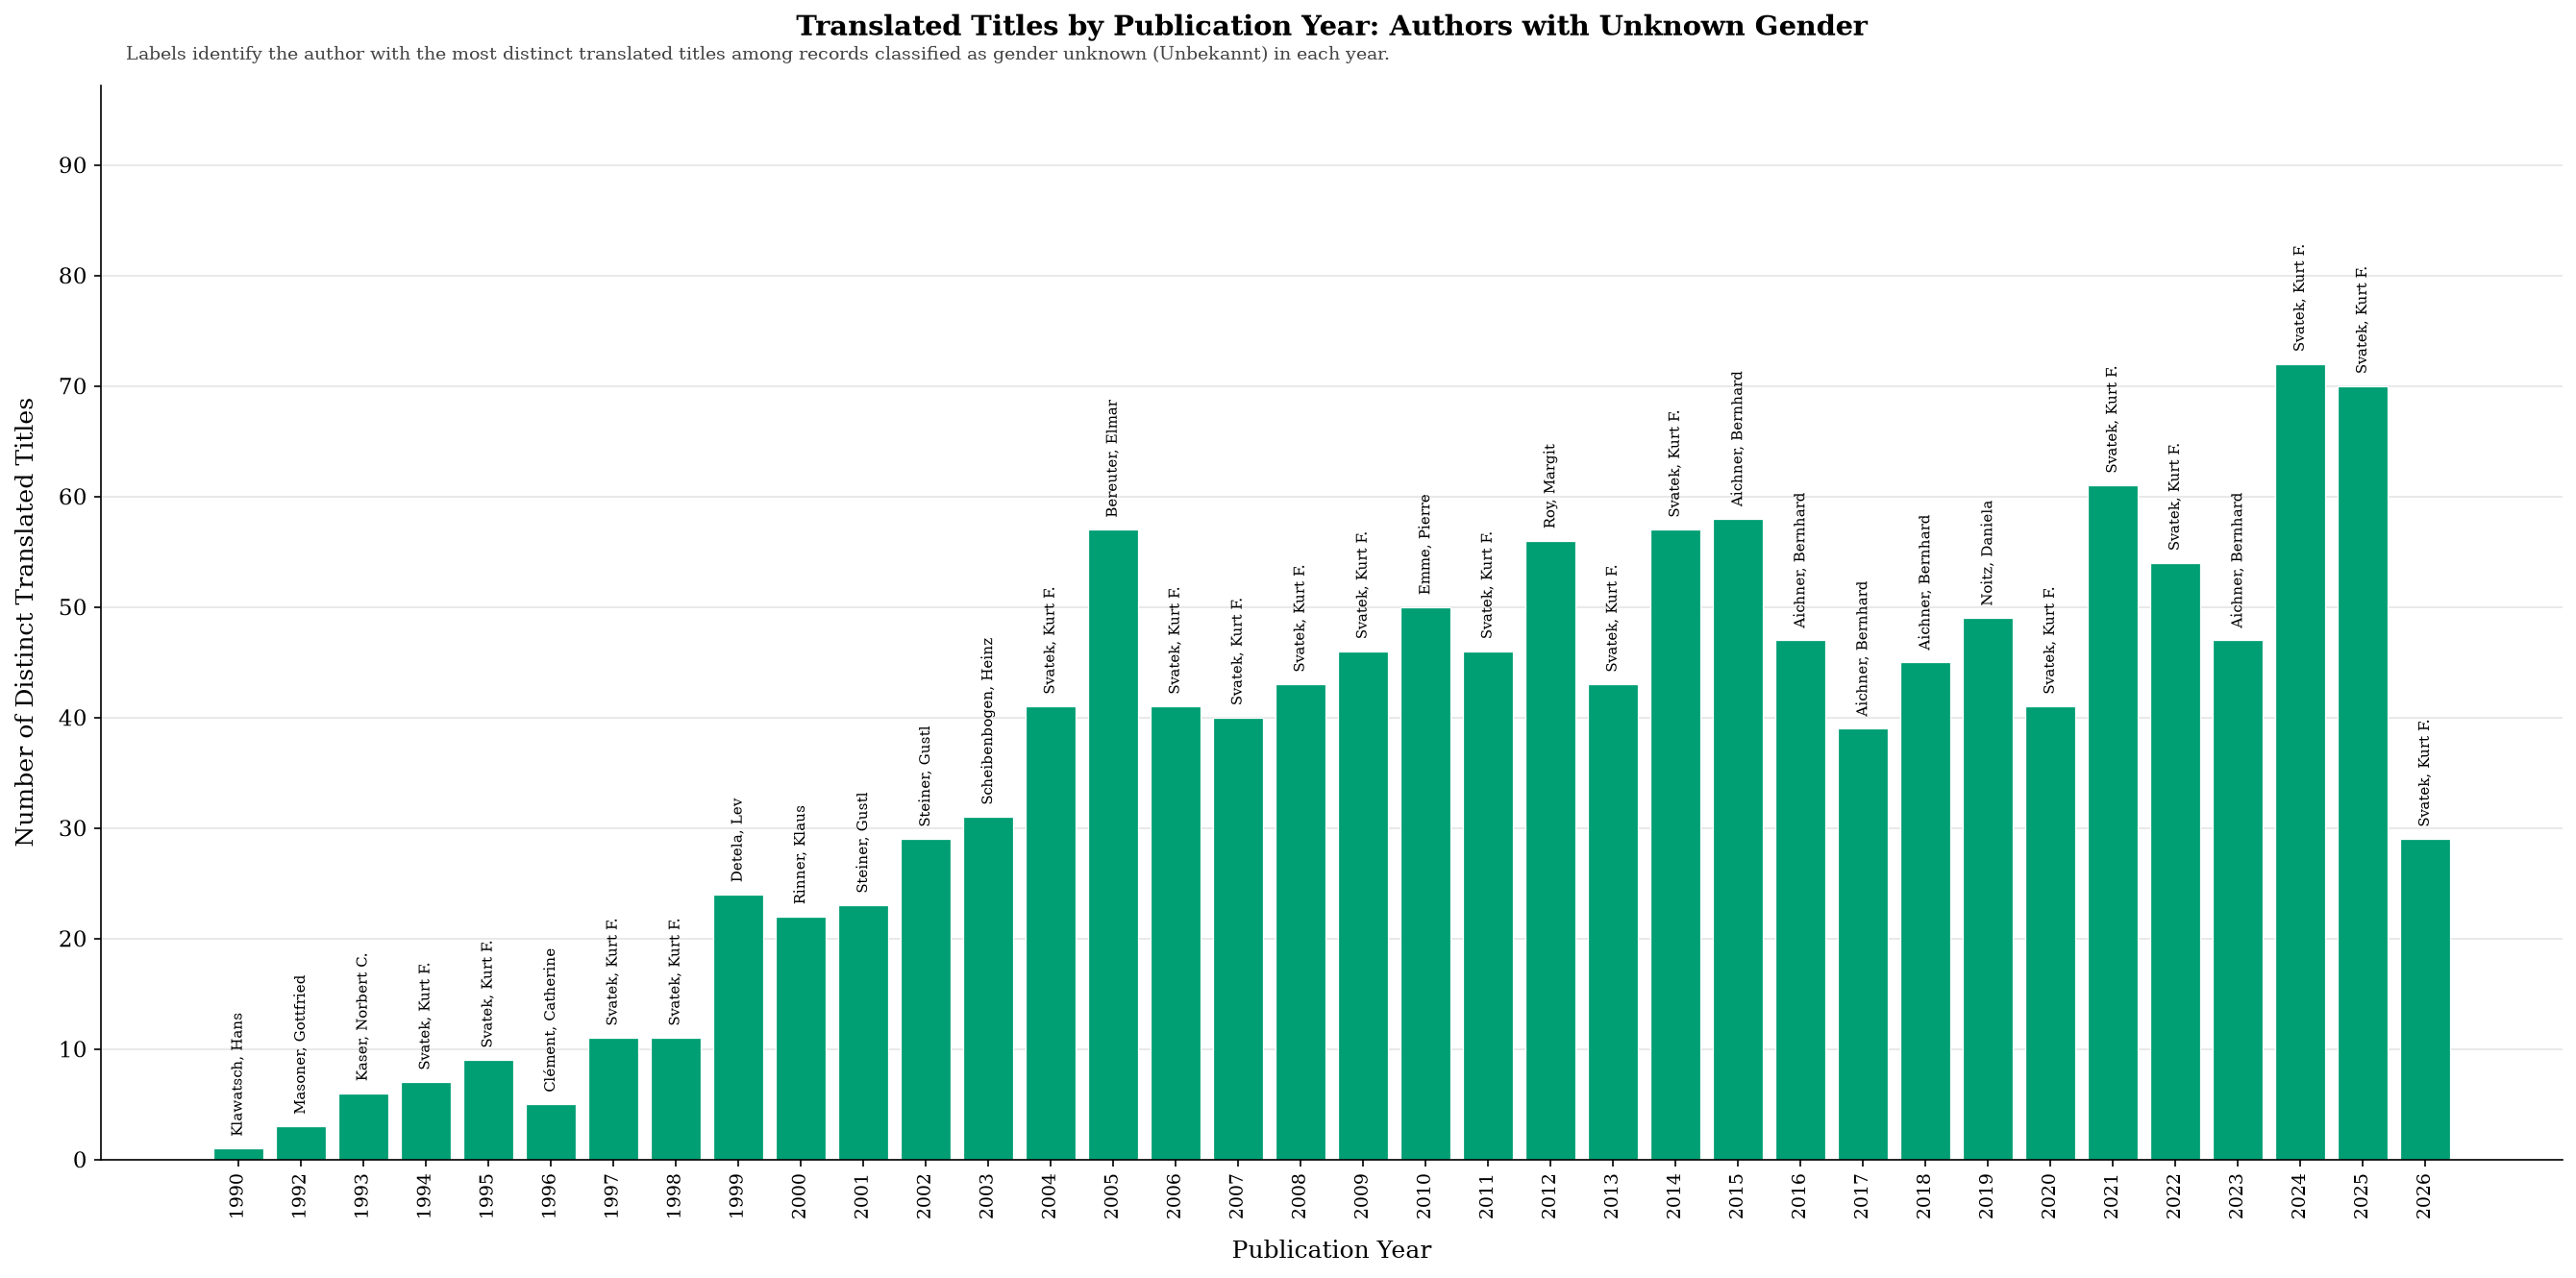

Saved PNG: /Users/lisateichmann/Desktop/ONB_gender/results/unknown_gender_titles_by_year_top_author.png
Saved PDF: /Users/lisateichmann/Desktop/ONB_gender/results/unknown_gender_titles_by_year_top_author.pdf


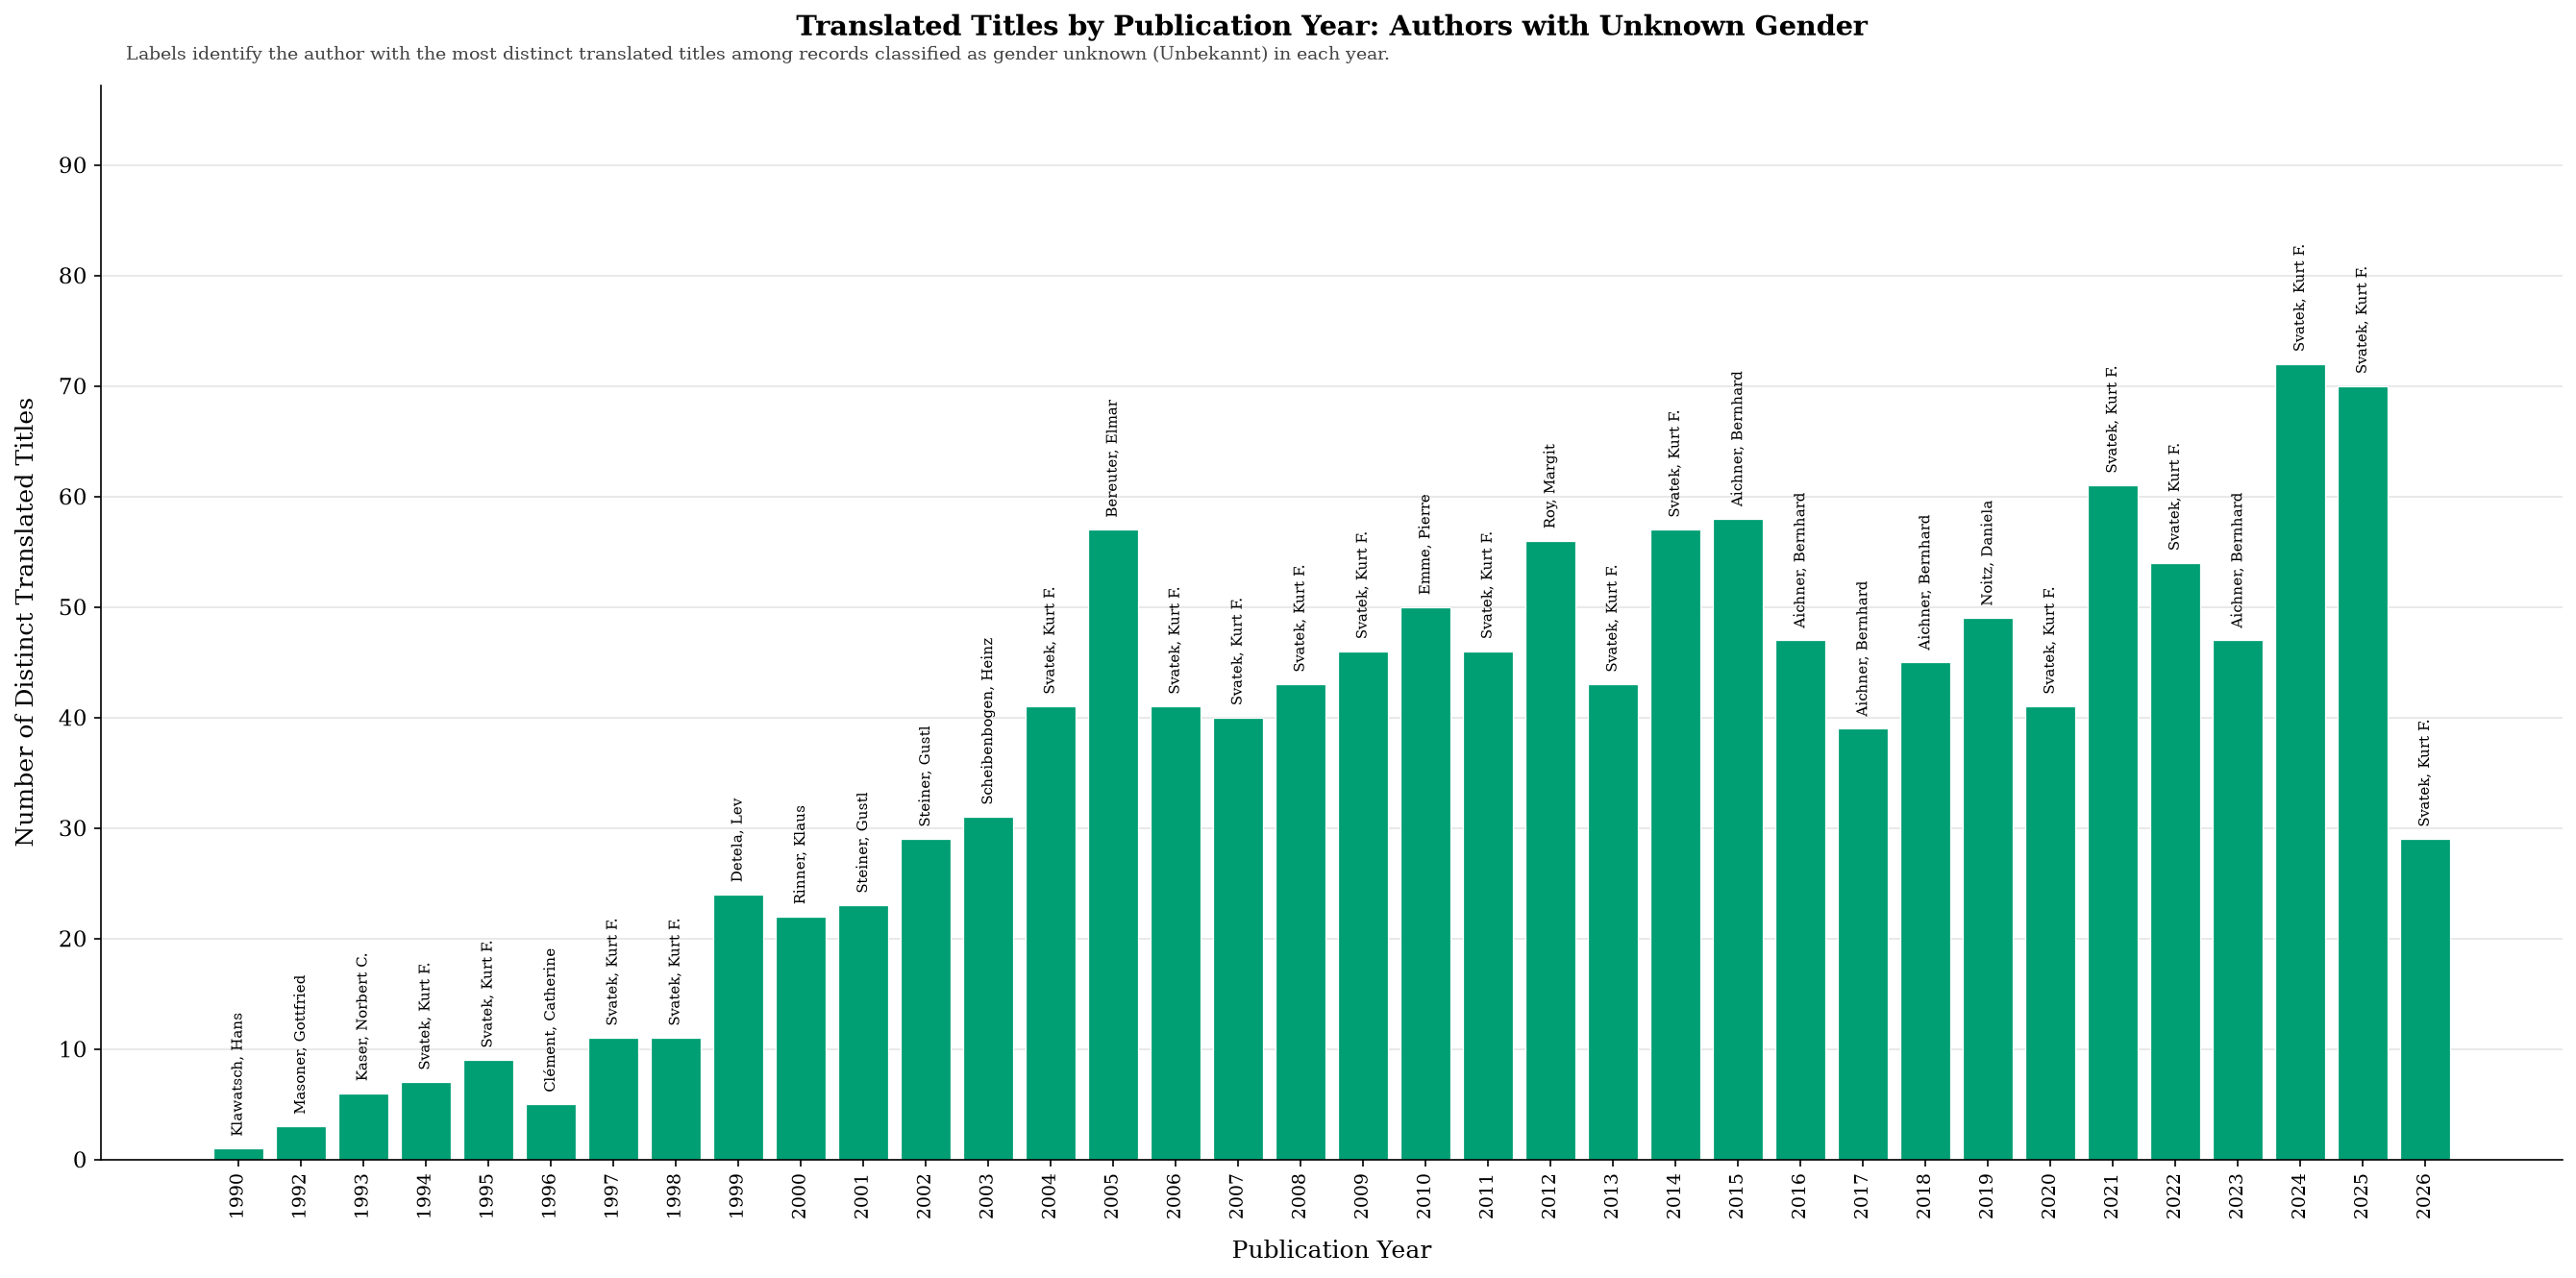

In [114]:
# ------------------------------------------------------------
# Authors with Geschlecht = "Unbekannt":
# Distinct translated titles by publication year
# Labels show the author with the most translated titles per year
# ------------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from pathlib import Path

# ------------------------------------------------------------
# 1. Keep needed columns and clean publication years
# ------------------------------------------------------------

data = df[
    [
        "publication_date",
        "Geschlecht",
        "author",
        "title"
    ]
].copy()

# Convert publication date to numeric values
data["publication_date"] = pd.to_numeric(
    data["publication_date"],
    errors="coerce"
)

# Remove rows without valid years
data = data.dropna(subset=["publication_date"])
data["publication_date"] = data["publication_date"].astype(int)

# Keep years from 1990 onward and remove invalid year
data = data[
    (data["publication_date"] > 1989) &
    (data["publication_date"] != 7519)
].copy()

# ------------------------------------------------------------
# 2. Keep only authors with gender = "Unbekannt"
# ------------------------------------------------------------

unknown_data = data.loc[
    data["Geschlecht"].eq("Unbekannt")
].copy()

# Clean author names
unknown_data["author"] = (
    unknown_data["author"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Clean title values
unknown_data["title"] = (
    unknown_data["title"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Retain only usable records
unknown_data = unknown_data.dropna(
    subset=["publication_date", "author", "title"]
).copy()

# Stop if there are no usable records
if unknown_data.empty:
    raise ValueError(
        "No usable records with Geschlecht = 'Unbekannt' were found. "
        "Check the exact values in df['Geschlecht']."
    )

# ------------------------------------------------------------
# 3. Count distinct translated titles per publication year
# ------------------------------------------------------------

unknown_titles_by_year = (
    unknown_data
    .groupby("publication_date")["title"]
    .nunique()
    .sort_index()
)

# ------------------------------------------------------------
# 4. Find the most translated unknown-gender author per year
# ------------------------------------------------------------

unknown_author_year_counts = (
    unknown_data
    .groupby(["publication_date", "author"])["title"]
    .nunique()
    .reset_index(name="translated_titles")
)

# Sort so that the leading author in each year comes first:
# - year ascending;
# - number of distinct titles descending;
# - alphabetical author name for tied counts.
unknown_author_year_counts = unknown_author_year_counts.sort_values(
    by=["publication_date", "translated_titles", "author"],
    ascending=[True, False, True]
)

# Keep the top author for each year
top_unknown_author_by_year = (
    unknown_author_year_counts
    .drop_duplicates(subset="publication_date", keep="first")
    .set_index("publication_date")
)

# Align author labels exactly with the bar-chart year order
top_unknown_labels = (
    top_unknown_author_by_year["author"]
    .reindex(unknown_titles_by_year.index)
)

# Optional: inspect the authors selected as top author each year
top_unknown_summary = pd.DataFrame({
    "year": unknown_titles_by_year.index,
    "distinct_titles_in_year": unknown_titles_by_year.values,
    "top_author": top_unknown_labels.values
})

print("Top author with Geschlecht = 'Unbekannt' in each publication year:")
display(top_unknown_summary)

# ------------------------------------------------------------
# 5. Plot styling
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "figure.dpi": 150,
    "savefig.dpi": 400
})

fig, ax = plt.subplots(
    figsize=(18, 9),
    facecolor="white"
)

# ------------------------------------------------------------
# 6. Draw yearly bar chart
# ------------------------------------------------------------

bar_colour = "#009E73"  # green, matching your earlier "Unbekannt" palette

bars = ax.bar(
    range(len(unknown_titles_by_year)),
    unknown_titles_by_year.values,
    color=bar_colour,
    edgecolor="white",
    linewidth=0.6,
    width=0.8
)

# Use actual publication years on the x-axis
ax.set_xticks(range(len(unknown_titles_by_year)))

ax.set_xticklabels(
    unknown_titles_by_year.index.astype(str),
    rotation=90,
    fontsize=9
)

# ------------------------------------------------------------
# 7. Label each bar with the leading author in that year
# ------------------------------------------------------------

max_titles = unknown_titles_by_year.max()

for x_position, (year, author) in enumerate(top_unknown_labels.items()):

    if pd.notna(author):

        bar_height = unknown_titles_by_year.loc[year]

        ax.text(
            x=x_position,
            y=bar_height + max_titles * 0.015,
            s=str(author),
            ha="center",
            va="bottom",
            rotation=90,
            fontsize=7,
            color="black",
            clip_on=False
        )

# ------------------------------------------------------------
# 8. Format chart
# ------------------------------------------------------------

ax.set_title(
    "Translated Titles by Publication Year: Authors with Unknown Gender",
    fontsize=14,
    fontweight="bold",
    pad=25
)

ax.set_xlabel(
    "Publication Year",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Number of Distinct Translated Titles",
    fontsize=12,
    labelpad=10
)

# Leave room above bars for the vertical author labels
ax.set_ylim(
    0,
    max_titles * 1.35
)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_axisbelow(True)

ax.grid(
    axis="y",
    color="#E5E5E5",
    linewidth=0.8
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Explanation above the chart
ax.text(
    0.01,
    1.02,
    (
        "Labels identify the author with the most distinct translated titles "
        "among records classified as gender unknown (Unbekannt) in each year."
    ),
    transform=ax.transAxes,
    fontsize=9,
    color="#444444",
    va="bottom"
)

# ------------------------------------------------------------
# 9. Save and display the figure
# ------------------------------------------------------------

output_folder = Path(
    "/Users/lisateichmann/Desktop/ONB_gender/results"
)

output_folder.mkdir(
    parents=True,
    exist_ok=True
)

fig.tight_layout()

png_path = (
    output_folder /
    "unknown_gender_titles_by_year_top_author.png"
)

pdf_path = (
    output_folder /
    "unknown_gender_titles_by_year_top_author.pdf"
)

# Save high-resolution PNG
fig.savefig(
    png_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

# Save vector PDF
fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

# Display the specific figure
display(fig)

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)